In [1]:
import torch
import torchvision
from torch import nn, optim
from torch.nn import functional as F
import matplotlib.pyplot as plt
from pylab import rcParams
import numpy as np
import os
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Set up plotting parameters
rcParams['figure.figsize'] = 8, 8
plt.ion()  # Interactive plotting

print("✅ All libraries imported successfully!")
print(f"PyTorch version: {torch.__version__}")
print(f"Using device: {'CUDA' if torch.cuda.is_available() else 'CPU'}")


✅ All libraries imported successfully!
PyTorch version: 2.15.0+cu132
Using device: CUDA


In [2]:
# Training configuration
BATCH_SIZE = 128        # How many data points to process at once
EPOCHS = 100           # How many times to see the entire dataset
LOG_INTERVAL = 50      # How often to print progress updates

# Model architecture
INPUT_DIM = 28 * 28    # Our data has 2 dimensions (x, y coordinates)
NOISE_DIM = 28 * 28    # Dimension of noise input to generator
HIDDEN_DIM = 2048      # Size of hidden layers in our neural networks

# GAN-specific hyperparameters
LR_G = 8e-4           # Learning rate for Generator
LR_D = 2e-4           # Learning rate for Discriminator
BETA1 = 0.5           # Beta1 for Adam optimizer

# Visualization settings
SAVE_PLT_INTERVAL = 5   # How often to save plots (every 5 epochs)

# Set up device (use GPU if available, otherwise CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(f"Batch size: {BATCH_SIZE}")
print(f"Epochs: {EPOCHS}")
print(f"Hidden dimension: {HIDDEN_DIM}")
print(f"Generator learning rate: {LR_G}")
print(f"Discriminator learning rate: {LR_D}")
print(f"Device: {device}")


Batch size: 128
Epochs: 100
Hidden dimension: 2048
Generator learning rate: 0.0008
Discriminator learning rate: 0.0002
Device: cuda


In [3]:
train_data = torchvision.datasets.MNIST(
    root='data/',
    train=True,
    download=True,
    transform=torchvision.transforms.Compose([torchvision.transforms.ToTensor(), torch.flatten])
)
test_data = torchvision.datasets.MNIST(
    root='data/',
    train=False,
    download=True,
    transform=torchvision.transforms.Compose([torchvision.transforms.ToTensor(), torch.flatten])
)

print(f"Training data shape: {train_data.data.shape}")
print(f"Test data shape: {test_data.data.shape}")

Training data shape: torch.Size([60000, 28, 28])
Test data shape: torch.Size([10000, 28, 28])


In [4]:
# Set up data loaders
# pin_memory=True speeds up data transfer to GPU (if available)
kwargs = {'num_workers': 4, 'pin_memory': True} if device.type == 'cuda' else {}

train_loader = torch.utils.data.DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    **kwargs
)

test_loader = torch.utils.data.DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    **kwargs
)

print(f"Batch size: {BATCH_SIZE}")
print(f"Training batches: {len(train_loader)}")
print(f"Test batches: {len(test_loader)}")

Batch size: 128
Training batches: 469
Test batches: 79


In [5]:
class Generator(nn.Module):
    """
    Generator network that creates fake data from random noise.
    
    The Generator takes random noise as input and transforms it into
    data that should look like our real moon-shaped data.
    """
    
    def __init__(self, noise_dim, output_dim, hidden_dim):
        super().__init__()
        
        # Build the neural network layers
        self.net = nn.Sequential(
            # Input layer: noise -> hidden
            nn.Linear(noise_dim, hidden_dim),
            nn.ReLU(),
            
            # Hidden layers
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            
            # Output layer: hidden -> data
            nn.Linear(hidden_dim, output_dim),
            # No activation on output - we want raw coordinates
        )
    
    def forward(self, noise):
        """
        Transform noise into fake data.
        
        Args:
            noise: Random noise tensor of shape (batch_size, noise_dim)
        
        Returns:
            fake_data: Generated data of shape (batch_size, output_dim)
        """
        return self.net(noise)


In [6]:
class Discriminator(nn.Module):
    """
    Discriminator network that distinguishes between real and fake data.
    
    The Discriminator takes data (real or fake) as input and outputs
    a probability that the data is real (closer to 1) or fake (closer to 0).
    """
    
    def __init__(self, input_dim, hidden_dim):
        super().__init__()
        
        # Build the neural network layers
        self.net = nn.Sequential(
            # Input layer: data -> hidden
            nn.Linear(input_dim, hidden_dim),
            nn.LeakyReLU(0.2),  # LeakyReLU helps with gradient flow
            
            # Hidden layers
            nn.Linear(hidden_dim, hidden_dim),
            nn.LeakyReLU(0.2),
            
            nn.Linear(hidden_dim, hidden_dim),
            nn.LeakyReLU(0.2),
            
            # Output layer: hidden -> probability
            nn.Linear(hidden_dim, 1),
            nn.Sigmoid()  # Output probability between 0 and 1
        )
    
    def forward(self, data):
        """
        Classify data as real or fake.
        
        Args:
            data: Input data tensor of shape (batch_size, input_dim)
        
        Returns:
            probability: Probability that data is real (0-1)
        """
        return self.net(data)


In [7]:
# Initialize models
generator = Generator(NOISE_DIM, INPUT_DIM, HIDDEN_DIM)
discriminator = Discriminator(INPUT_DIM, HIDDEN_DIM)

# Move models to device and ensure correct dtype
generator = generator.to(device).float()
discriminator = discriminator.to(device).float()

# Set up optimizers for both networks
# We use different optimizers for Generator and Discriminator
optimizer_G = torch.optim.Adam(generator.parameters(), lr=LR_G, betas=(BETA1, 0.999))
optimizer_D = torch.optim.Adam(discriminator.parameters(), lr=LR_D, betas=(BETA1, 0.999))

# Loss function for GAN training
criterion = nn.BCELoss()  # Binary Cross Entropy Loss

print(f"Generator parameters: {sum(p.numel() for p in generator.parameters()):,}")
print(f"Discriminator parameters: {sum(p.numel() for p in discriminator.parameters()):,}")
print(f"Generator learning rate: {LR_G}")
print(f"Discriminator learning rate: {LR_D}")
print(f"Models moved to device: {device}")
print(f"Models dtype: {next(generator.parameters()).dtype}")

# Let's see what our models look like
print("\nGenerator architecture:")
print(generator)
print("\nDiscriminator architecture:")
print(discriminator)


Generator parameters: 11,606,800
Discriminator parameters: 10,002,433
Generator learning rate: 0.0008
Discriminator learning rate: 0.0002
Models moved to device: cuda
Models dtype: torch.float32

Generator architecture:
Generator(
  (net): Sequential(
    (0): Linear(in_features=784, out_features=2048, bias=True)
    (1): ReLU()
    (2): Linear(in_features=2048, out_features=2048, bias=True)
    (3): ReLU()
    (4): Linear(in_features=2048, out_features=2048, bias=True)
    (5): ReLU()
    (6): Linear(in_features=2048, out_features=784, bias=True)
  )
)

Discriminator architecture:
Discriminator(
  (net): Sequential(
    (0): Linear(in_features=784, out_features=2048, bias=True)
    (1): LeakyReLU(negative_slope=0.2)
    (2): Linear(in_features=2048, out_features=2048, bias=True)
    (3): LeakyReLU(negative_slope=0.2)
    (4): Linear(in_features=2048, out_features=2048, bias=True)
    (5): LeakyReLU(negative_slope=0.2)
    (6): Linear(in_features=2048, out_features=1, bias=True)
    (7

In [8]:
# Complete visualization function with validation support
def visualize_training_progress_complete(epoch, train_d_losses, train_g_losses, val_d_losses=None, val_g_losses=None):
    """
    Complete visualization function for GAN training progress with validation support.
    
    Args:
        epoch: Current epoch number
        train_d_losses: List of discriminator training losses
        train_g_losses: List of generator training losses
        val_d_losses: List of discriminator validation losses (optional)
        val_g_losses: List of generator validation losses (optional)
    """
    # Generate samples
    fake_samples = generate_samples(train_data.shape[0])
    
    # Create visualization with 2x3 subplots
    plt.figure(figsize=(18, 10))
    
    # Original training data
    plt.subplot(2, 3, 1)
    plt.scatter(train_data[:, 0], train_data[:, 1], c='blue', s=1, alpha=0.6)
    plt.title('Real Training Data\\n(Moons + Circles)')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.grid(True, alpha=0.3)
    
    # Generated samples
    plt.subplot(2, 3, 2)
    plt.scatter(fake_samples[:, 0], fake_samples[:, 1], c='red', s=1, alpha=0.6)
    plt.title(f'Generated Samples (Epoch {epoch})')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.grid(True, alpha=0.3)
    
    # Overlay comparison
    plt.subplot(2, 3, 3)
    plt.scatter(train_data[:2000, 0], train_data[:2000, 1], c='blue', s=1, alpha=0.3, label='Real')
    plt.scatter(fake_samples[:, 0], fake_samples[:, 1], c='red', s=1, alpha=0.3, label='Generated')
    plt.title('Comparison (Real vs Generated)')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Skip first 5 epochs for loss plotting (due to big magnitude)
    skip_epochs = 5
    if len(train_d_losses) > skip_epochs:
        # Discriminator losses (skip first 5 epochs)
        plt.subplot(2, 3, 4)
        epochs_range = range(skip_epochs + 1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        if val_d_losses and len(val_d_losses) > skip_epochs:
            plt.plot(epochs_range, val_d_losses[skip_epochs:], 'b--', label='Val D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title(f'Discriminator Training Progress\\n(Skipping first {skip_epochs} epochs)')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Generator losses (skip first 5 epochs)
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        if val_g_losses and len(val_g_losses) > skip_epochs:
            plt.plot(epochs_range, val_g_losses[skip_epochs:], 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title(f'Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Combined loss plot (skip first 5 epochs)
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        if val_d_losses and val_g_losses and len(val_d_losses) > skip_epochs and len(val_g_losses) > skip_epochs:
            plt.plot(epochs_range, val_d_losses[skip_epochs:], 'b--', label='Val D Loss', linewidth=2)
            plt.plot(epochs_range, val_g_losses[skip_epochs:], 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title(f'Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    else:
        # If we don't have enough epochs yet, show all
        plt.subplot(2, 3, 4)
        epochs_range = range(1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        if val_d_losses and len(val_d_losses) > 0:
            plt.plot(epochs_range, val_d_losses, 'b--', label='Val D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title('Discriminator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        if val_g_losses and len(val_g_losses) > 0:
            plt.plot(epochs_range, val_g_losses, 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title('Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        if val_d_losses and val_g_losses and len(val_d_losses) > 0 and len(val_g_losses) > 0:
            plt.plot(epochs_range, val_d_losses, 'b--', label='Val D Loss', linewidth=2)
            plt.plot(epochs_range, val_g_losses, 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()


In [9]:
# Ensure train_discriminator function is defined (in case cells weren't executed in order)
def train_discriminator(real_data, batch_size):
    """
    Train the Discriminator to distinguish between real and fake data.
    
    Args:
        real_data: Batch of real data from our dataset
        batch_size: Size of the batch
    
    Returns:
        d_loss: Discriminator loss for this batch
    """
    # Clear gradients
    optimizer_D.zero_grad()
    
    # Ensure data is on correct device and dtype
    real_data = real_data.to(device).float()
    
    # Train on real data
    # Create labels for real data (all should be 1)
    real_labels = torch.ones(batch_size, 1, dtype=torch.float32).to(device)
    
    # Get discriminator predictions on real data
    real_output = discriminator(real_data)
    
    # Compute loss for real data (we want high probability)
    real_loss = criterion(real_output, real_labels)
    
    # Train on fake data
    # Generate fake data using the generator
    noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
    fake_data = generator(noise)
    
    # Create labels for fake data (all should be 0)
    fake_labels = torch.zeros(batch_size, 1, device=device, dtype=torch.float32)
    
    # Get discriminator predictions on fake data
    fake_output = discriminator(fake_data.detach())  # detach() prevents gradients flowing to generator
    
    # Compute loss for fake data (we want low probability)
    fake_loss = criterion(fake_output, fake_labels)
    
    # Total discriminator loss
    d_loss = real_loss + fake_loss
    
    # Backpropagate and update discriminator
    d_loss.backward()
    optimizer_D.step()
    
    return d_loss.item()

def evaluate_discriminator(real_data, batch_size):
    """
    Evaluate the Discriminator on validation data (no training).
    
    Args:
        real_data: Batch of real data from our dataset
        batch_size: Size of the batch
    
    Returns:
        d_loss: Discriminator loss for this batch
    """
    with torch.no_grad():
        # Ensure data is on correct device and dtype
        real_data = real_data.to(device).float()
        
        # Evaluate on real data
        real_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
        real_output = discriminator(real_data)
        real_loss = criterion(real_output, real_labels)
        
        # Evaluate on fake data
        noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
        fake_data = generator(noise)
        fake_labels = torch.zeros(batch_size, 1, device=device, dtype=torch.float32)
        fake_output = discriminator(fake_data)
        fake_loss = criterion(fake_output, fake_labels)
        
        # Total discriminator loss
        d_loss = real_loss + fake_loss
        
    return d_loss.item()

In [10]:
def train_generator(batch_size):
    """
    Train the Generator to create data that fools the Discriminator.
    
    Args:
        batch_size: Size of the batch
    
    Returns:
        g_loss: Generator loss for this batch
    """
    # Clear gradients
    optimizer_G.zero_grad()
    
    # Generate fake data
    noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
    fake_data = generator(noise)
    
    # Create labels for fake data (we want discriminator to think it's real)
    fake_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
    
    # Get discriminator predictions on fake data
    fake_output = discriminator(fake_data)
    
    # Compute generator loss (we want discriminator to output high probability)
    g_loss = criterion(fake_output, fake_labels)
    
    # Backpropagate and update generator
    g_loss.backward()
    optimizer_G.step()
    
    return g_loss.item()

def evaluate_generator(batch_size):
    """
    Evaluate the Generator on validation data (no training).
    
    Args:
        batch_size: Size of the batch
    
    Returns:
        g_loss: Generator loss for this batch
    """
    with torch.no_grad():
        # Generate fake data
        noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
        fake_data = generator(noise)
        
        # Create labels for fake data (we want discriminator to think it's real)
        fake_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
        
        # Get discriminator predictions on fake data
        fake_output = discriminator(fake_data)
        
        # Compute generator loss (we want discriminator to output high probability)
        g_loss = criterion(fake_output, fake_labels)
        
    return g_loss.item()


In [11]:
def train_epoch_with_validation(epoch):
    """
    Train both Generator and Discriminator for one epoch with validation.
    
    Args:
        epoch: Current epoch number
    
    Returns:
        avg_d_loss: Average discriminator training loss for this epoch
        avg_g_loss: Average generator training loss for this epoch
        val_d_loss: Average discriminator validation loss
        val_g_loss: Average generator validation loss
    """
    # Set models to training mode
    generator.train()
    discriminator.train()
    
    # Track losses
    d_losses = []
    g_losses = []
    
    for batch_idx, (data, labels) in enumerate(train_loader):
        batch_size = data.size(0)
        data = data.to(device)
        
        # Train Discriminator
        d_loss = train_discriminator(data, batch_size)
        d_losses.append(d_loss)

        # Train Generator
        g_loss = train_generator(batch_size)
        g_losses.append(g_loss)
        
        # Print progress
        if batch_idx % LOG_INTERVAL == 0:
            print('Epoch: {} [{}/{} ({:.0f}%)]\tD_loss: {:.6f}\tG_loss: {:.6f}'.format(
                epoch, batch_idx * len(data), len(train_loader.dataset),
                100. * batch_idx / len(train_loader), d_loss, g_loss))
    
    # Calculate average training losses
    avg_d_loss = sum(d_losses) / len(d_losses)
    avg_g_loss = sum(g_losses) / len(g_losses)
    
    # Evaluate on validation set
    generator.eval()
    discriminator.eval()
    
    val_d_losses = []
    val_g_losses = []
    
    for batch_idx, (data, labels) in enumerate(test_loader):
        batch_size = data.size(0)
        
        # Evaluate Discriminator
        val_d_loss = evaluate_discriminator(data, batch_size)
        val_d_losses.append(val_d_loss)
        
        # Evaluate Generator
        val_g_loss = evaluate_generator(batch_size)
        val_g_losses.append(val_g_loss)
    
    # Calculate average validation losses
    val_d_loss = sum(val_d_losses) / len(val_d_losses)
    val_g_loss = sum(val_g_losses) / len(val_g_losses)
    
    print('====> Epoch: {} Train D_loss: {:.4f}, Train G_loss: {:.4f}'.format(
        epoch, avg_d_loss, avg_g_loss))
    print('====> Epoch: {} Val D_loss: {:.4f}, Val G_loss: {:.4f}'.format(
        epoch, val_d_loss, val_g_loss))
    
    return avg_d_loss, avg_g_loss, val_d_loss, val_g_loss


In [12]:
def generate_samples(num_samples=1000):
    """
    Generate fake samples using the current Generator.
    
    Args:
        num_samples: Number of samples to generate
    
    Returns:
        fake_samples: Generated data as numpy array
    """
    generator.eval()  # Set to evaluation mode
    
    with torch.no_grad():  # Don't compute gradients
        # Generate random noise with correct device and dtype
        noise = torch.randn(num_samples, NOISE_DIM, device=device, dtype=torch.float32)
        
        # Generate fake data
        fake_samples = generator(noise)
        
        # Convert to numpy for visualization
        fake_samples = fake_samples.cpu().numpy()
    
    return fake_samples


def pca_fit(data):
    pipeline = Pipeline([
        ('scaling', StandardScaler()),
        ('pca', PCA(n_components=2))
    ])
    pipeline.fit(data)

    return pipeline

In [13]:
# Simplified visualization function without validation
def visualize_training_progress(epoch, train_d_losses, train_g_losses, val_d_losses, val_g_losses):
    """
    Visualize the current state of our GAN training with loss plots.
    
    Args:
        epoch: Current epoch number
        train_d_losses: List of discriminator training losses
        train_g_losses: List of generator training losses
        save_plot: Whether to save the plot to disk
    """
    # Generate samples
    generated_samples = generate_samples(2000)
    
    # Create visualization with 2x3 subplots
    plt.figure(figsize=(18, 10))

    train_data_reshaped = np.reshape(train_data.data[:2000], [2000, INPUT_DIM])
    data_transformed = pca_fit(train_data_reshaped).transform(train_data_reshaped)
    x_transformed = pca_fit(generated_samples).transform(generated_samples)

    # Original training data
    plt.subplot(2, 3, 1)
    plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.6)
    plt.title('Original Training Data')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.grid(True, alpha=0.3)

    # Generated samples
    plt.subplot(2, 3, 2)
    plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.6)
    plt.title('Generated Samples')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.grid(True, alpha=0.3)

    # Overlay comparison
    plt.subplot(2, 3, 3)
    plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.3, label='Original')
    plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.3, label='Generated')
    plt.title('Overlay Comparison')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Skip first 5 epochs for loss plotting (due to big magnitude)
    skip_epochs = 5
    if len(train_d_losses) > skip_epochs:
        # Discriminator losses (skip first 5 epochs)
        plt.subplot(2, 3, 4)
        epochs_range = range(skip_epochs + 1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title(f'Discriminator Training Progress\n(Skipping first {skip_epochs} epochs)')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Generator losses (skip first 5 epochs)
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title(f'Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Combined loss plot (skip first 5 epochs)
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title(f'Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    else:
        # If we don't have enough epochs yet, show all
        plt.subplot(2, 3, 4)
        epochs_range = range(1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title('Discriminator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title('Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    
    plt.show()


🎯 Starting GAN training...
📊 Initial state (before training):

📊 Epoch 1/100
----------------------------------------
Epoch: 1 [0/60000 (0%)]	D_loss: 1.389258	G_loss: 0.685649
Epoch: 1 [6400/60000 (11%)]	D_loss: 1.398622	G_loss: 0.772971
Epoch: 1 [12800/60000 (21%)]	D_loss: 1.391401	G_loss: 0.717968
Epoch: 1 [19200/60000 (32%)]	D_loss: 1.339221	G_loss: 0.761609
Epoch: 1 [25600/60000 (43%)]	D_loss: 1.422180	G_loss: 0.781882
Epoch: 1 [32000/60000 (53%)]	D_loss: 1.155836	G_loss: 1.359386
Epoch: 1 [38400/60000 (64%)]	D_loss: 0.209583	G_loss: 20.088451
Epoch: 1 [44800/60000 (75%)]	D_loss: 0.215473	G_loss: 4.461747
Epoch: 1 [51200/60000 (85%)]	D_loss: 0.030592	G_loss: 6.503018
Epoch: 1 [57600/60000 (96%)]	D_loss: 0.052729	G_loss: 5.799406
====> Epoch: 1 Train D_loss: 0.9372, Train G_loss: 3.3157
====> Epoch: 1 Val D_loss: 0.3534, Val G_loss: 2.7894
📈 Epoch 1 Summary:
   Train D Loss: 0.9372, Val D Loss: 0.3534
   Train G Loss: 3.3157, Val G Loss: 2.7894

📊 Epoch 2/100
-----------------------

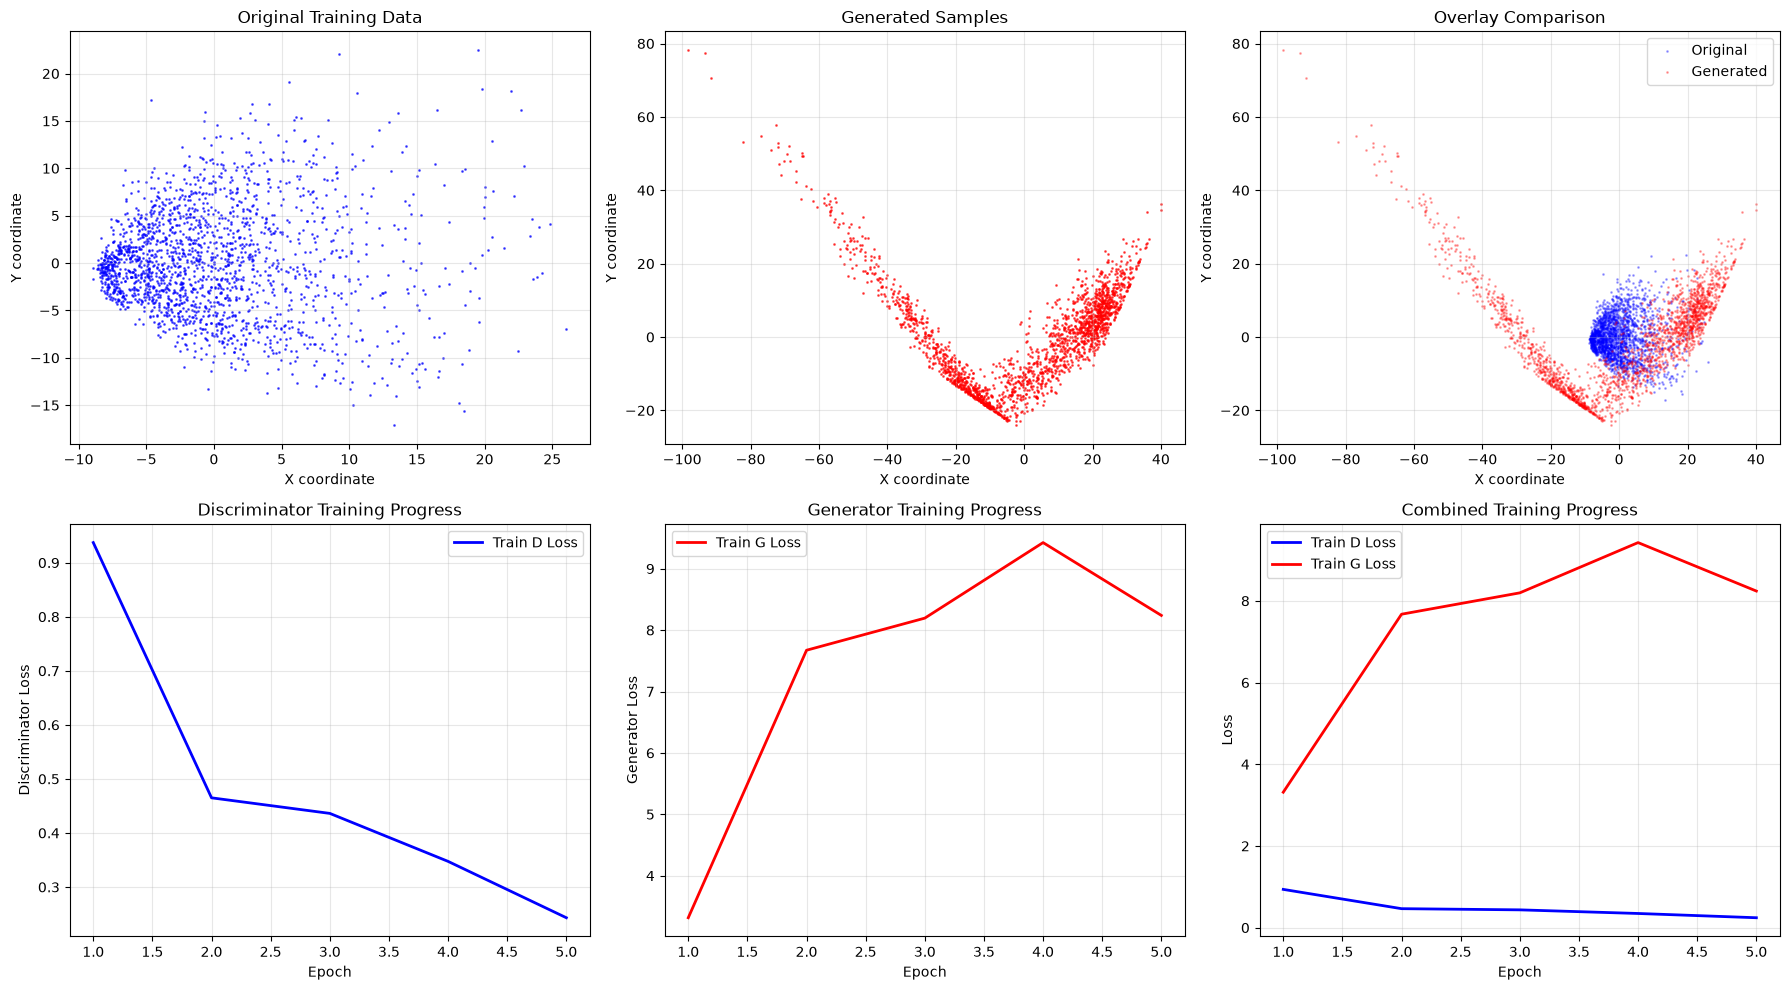

📈 Epoch 5 Summary:
   Train D Loss: 0.2432, Val D Loss: 0.0316
   Train G Loss: 8.2391, Val G Loss: 5.9194

📊 Epoch 6/100
----------------------------------------
Epoch: 6 [0/60000 (0%)]	D_loss: 0.019971	G_loss: 6.508395
Epoch: 6 [6400/60000 (11%)]	D_loss: 0.153206	G_loss: 6.568435
Epoch: 6 [12800/60000 (21%)]	D_loss: 0.051958	G_loss: 7.536330
Epoch: 6 [19200/60000 (32%)]	D_loss: 0.161711	G_loss: 8.697699
Epoch: 6 [25600/60000 (43%)]	D_loss: 0.041981	G_loss: 5.846916
Epoch: 6 [32000/60000 (53%)]	D_loss: 0.702555	G_loss: 40.592453
Epoch: 6 [38400/60000 (64%)]	D_loss: 0.088125	G_loss: 7.187274
Epoch: 6 [44800/60000 (75%)]	D_loss: 0.096735	G_loss: 4.145474
Epoch: 6 [51200/60000 (85%)]	D_loss: 0.160192	G_loss: 6.072567
Epoch: 6 [57600/60000 (96%)]	D_loss: 0.051730	G_loss: 6.168672
====> Epoch: 6 Train D_loss: 0.2762, Train G_loss: 9.1370
====> Epoch: 6 Val D_loss: 0.2202, Val G_loss: 2.8003
📈 Epoch 6 Summary:
   Train D Loss: 0.2762, Val D Loss: 0.2202
   Train G Loss: 9.1370, Val G Loss: 

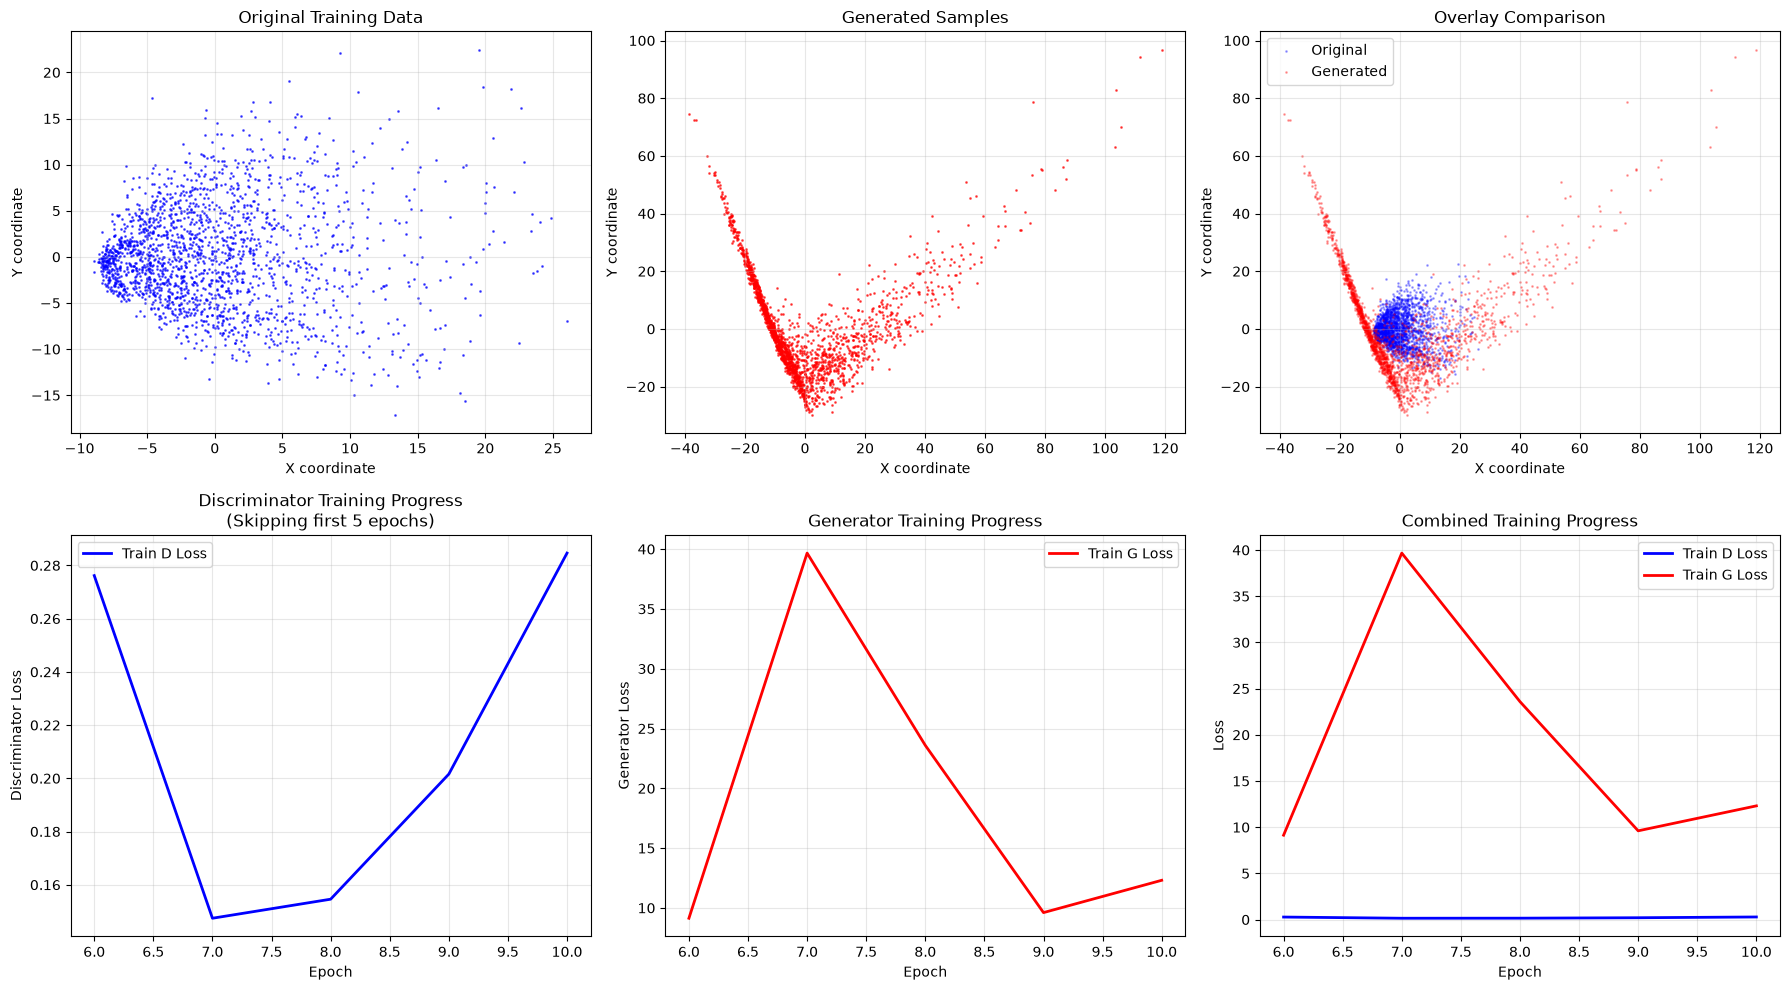

📈 Epoch 10 Summary:
   Train D Loss: 0.2846, Val D Loss: 0.1579
   Train G Loss: 12.3094, Val G Loss: 6.6483

📊 Epoch 11/100
----------------------------------------
Epoch: 11 [0/60000 (0%)]	D_loss: 0.028594	G_loss: 10.257938
Epoch: 11 [6400/60000 (11%)]	D_loss: 0.222641	G_loss: 7.312629
Epoch: 11 [12800/60000 (21%)]	D_loss: 0.114359	G_loss: 6.242719
Epoch: 11 [19200/60000 (32%)]	D_loss: 0.175777	G_loss: 6.532643
Epoch: 11 [25600/60000 (43%)]	D_loss: 0.612680	G_loss: 8.193198
Epoch: 11 [32000/60000 (53%)]	D_loss: 0.128393	G_loss: 5.797436
Epoch: 11 [38400/60000 (64%)]	D_loss: 0.178566	G_loss: 4.797178
Epoch: 11 [44800/60000 (75%)]	D_loss: 0.269769	G_loss: 6.025143
Epoch: 11 [51200/60000 (85%)]	D_loss: 0.673902	G_loss: 9.493143
Epoch: 11 [57600/60000 (96%)]	D_loss: 0.153198	G_loss: 6.003027
====> Epoch: 11 Train D_loss: 0.3002, Train G_loss: 7.9685
====> Epoch: 11 Val D_loss: 1.2790, Val G_loss: 22.2159
📈 Epoch 11 Summary:
   Train D Loss: 0.3002, Val D Loss: 1.2790
   Train G Loss: 7.9

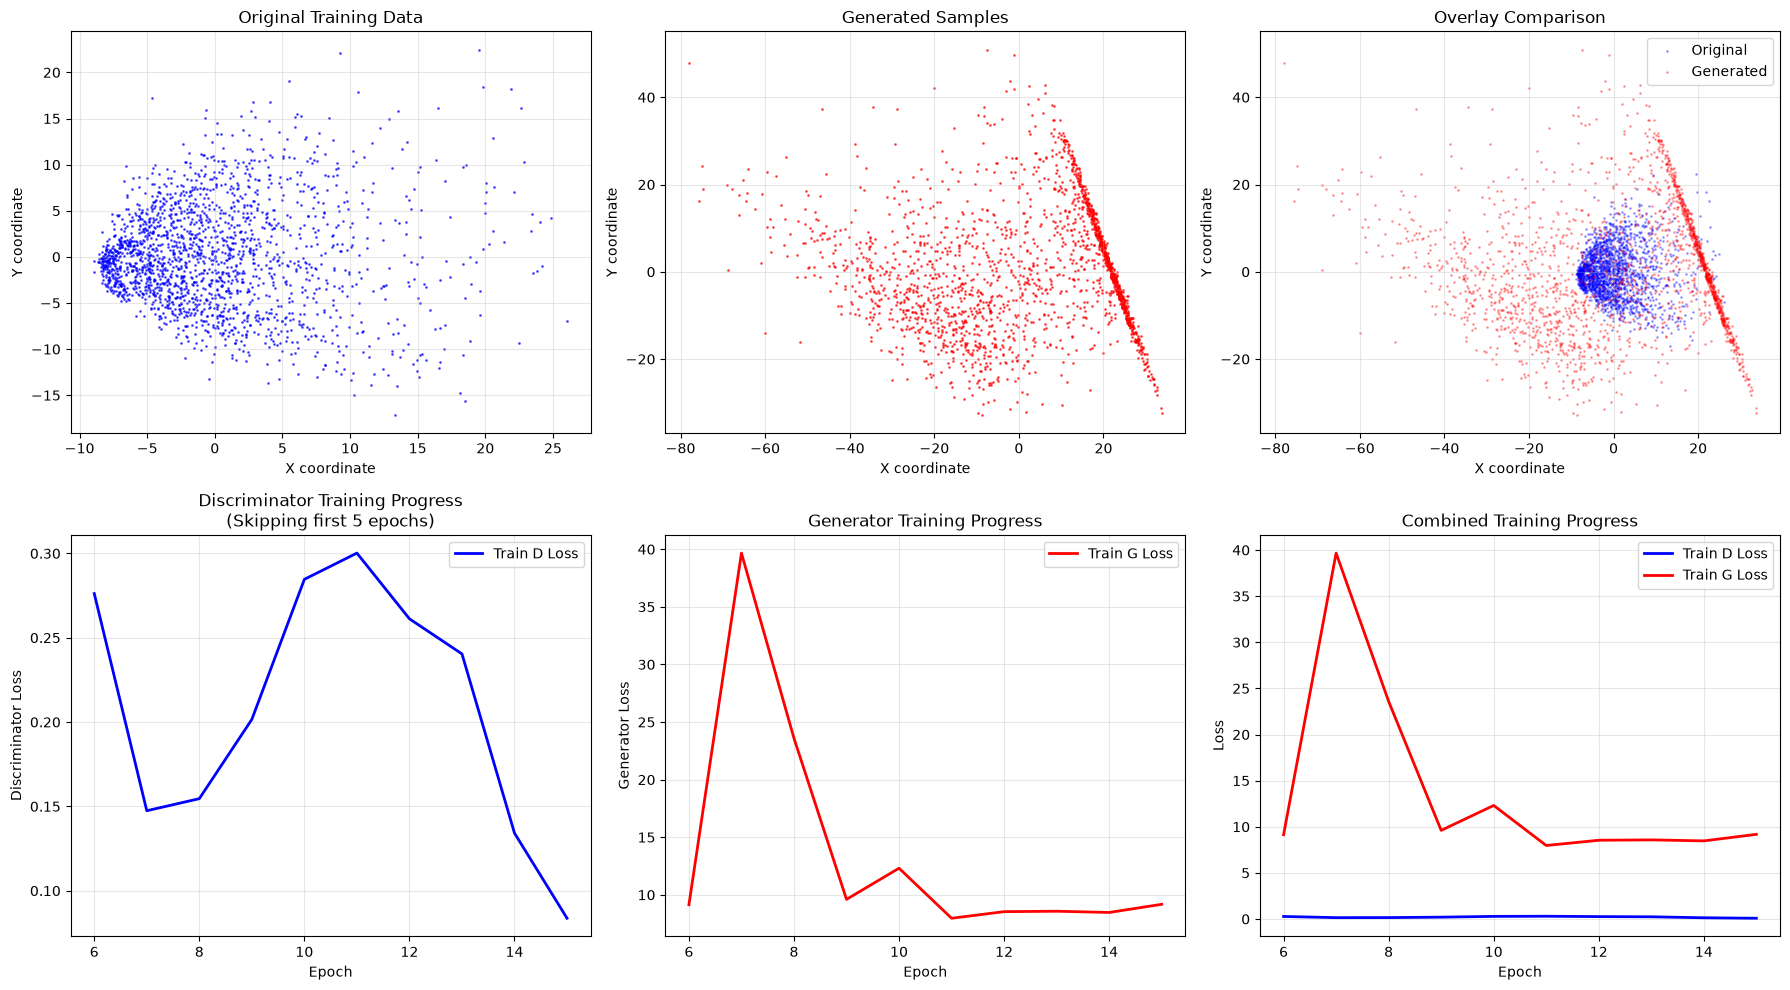

📈 Epoch 15 Summary:
   Train D Loss: 0.0837, Val D Loss: 0.2875
   Train G Loss: 9.1786, Val G Loss: 7.2718

📊 Epoch 16/100
----------------------------------------
Epoch: 16 [0/60000 (0%)]	D_loss: 0.220679	G_loss: 16.939915
Epoch: 16 [6400/60000 (11%)]	D_loss: 0.087680	G_loss: 5.570082
Epoch: 16 [12800/60000 (21%)]	D_loss: 0.079053	G_loss: 61.826569
Epoch: 16 [19200/60000 (32%)]	D_loss: 0.000675	G_loss: 19.498428
Epoch: 16 [25600/60000 (43%)]	D_loss: 0.029788	G_loss: 6.533556
Epoch: 16 [32000/60000 (53%)]	D_loss: 0.064189	G_loss: 7.522299
Epoch: 16 [38400/60000 (64%)]	D_loss: 0.184209	G_loss: 9.304146
Epoch: 16 [44800/60000 (75%)]	D_loss: 0.061430	G_loss: 5.413719
Epoch: 16 [51200/60000 (85%)]	D_loss: 0.227867	G_loss: 12.283201
Epoch: 16 [57600/60000 (96%)]	D_loss: 0.063741	G_loss: 8.424250
====> Epoch: 16 Train D_loss: 0.1131, Train G_loss: 13.4332
====> Epoch: 16 Val D_loss: 0.1056, Val G_loss: 5.1756
📈 Epoch 16 Summary:
   Train D Loss: 0.1131, Val D Loss: 0.1056
   Train G Loss: 1

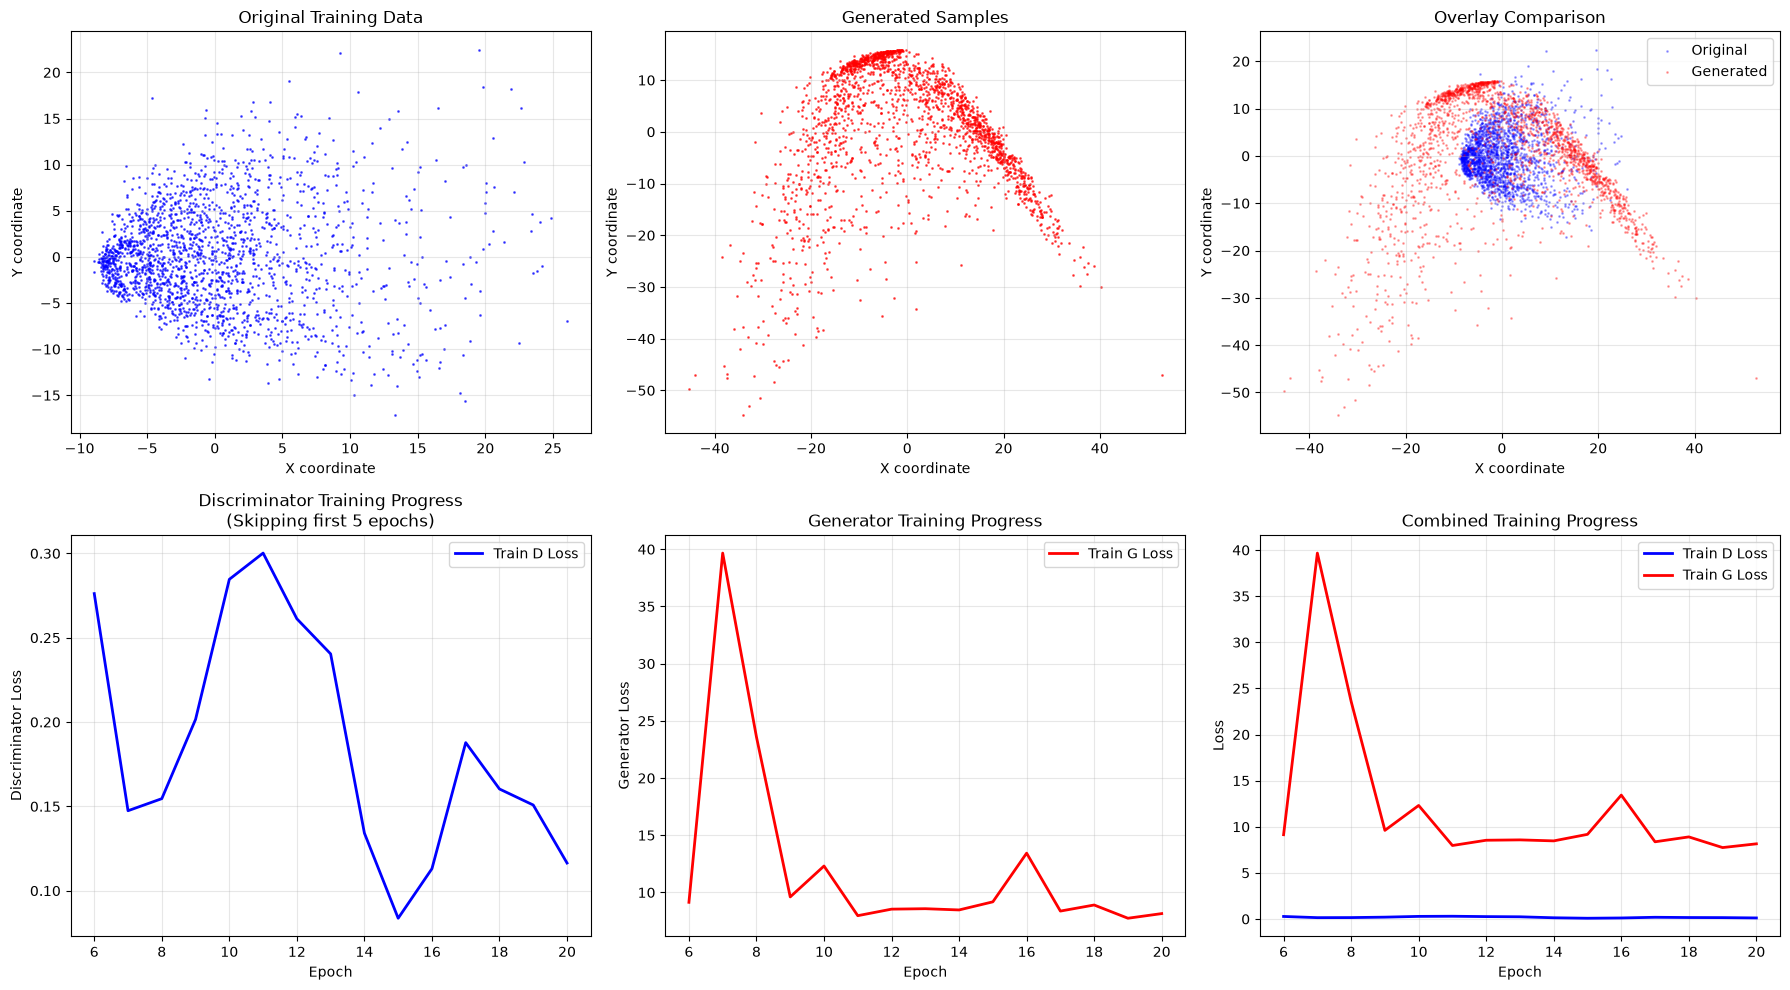

📈 Epoch 20 Summary:
   Train D Loss: 0.1164, Val D Loss: 0.1470
   Train G Loss: 8.1500, Val G Loss: 4.5579

📊 Epoch 21/100
----------------------------------------
Epoch: 21 [0/60000 (0%)]	D_loss: 0.136360	G_loss: 9.766467
Epoch: 21 [6400/60000 (11%)]	D_loss: 0.052436	G_loss: 6.493541
Epoch: 21 [12800/60000 (21%)]	D_loss: 0.214621	G_loss: 12.293556
Epoch: 21 [19200/60000 (32%)]	D_loss: 0.059149	G_loss: 6.846619
Epoch: 21 [25600/60000 (43%)]	D_loss: 0.127469	G_loss: 7.346504
Epoch: 21 [32000/60000 (53%)]	D_loss: 0.048180	G_loss: 7.180630
Epoch: 21 [38400/60000 (64%)]	D_loss: 0.192480	G_loss: 5.565984
Epoch: 21 [44800/60000 (75%)]	D_loss: 0.083759	G_loss: 7.350095
Epoch: 21 [51200/60000 (85%)]	D_loss: 0.248656	G_loss: 6.770637
Epoch: 21 [57600/60000 (96%)]	D_loss: 0.364321	G_loss: 11.960779
====> Epoch: 21 Train D_loss: 0.1199, Train G_loss: 7.5220
====> Epoch: 21 Val D_loss: 0.1017, Val G_loss: 4.8945
📈 Epoch 21 Summary:
   Train D Loss: 0.1199, Val D Loss: 0.1017
   Train G Loss: 7.52

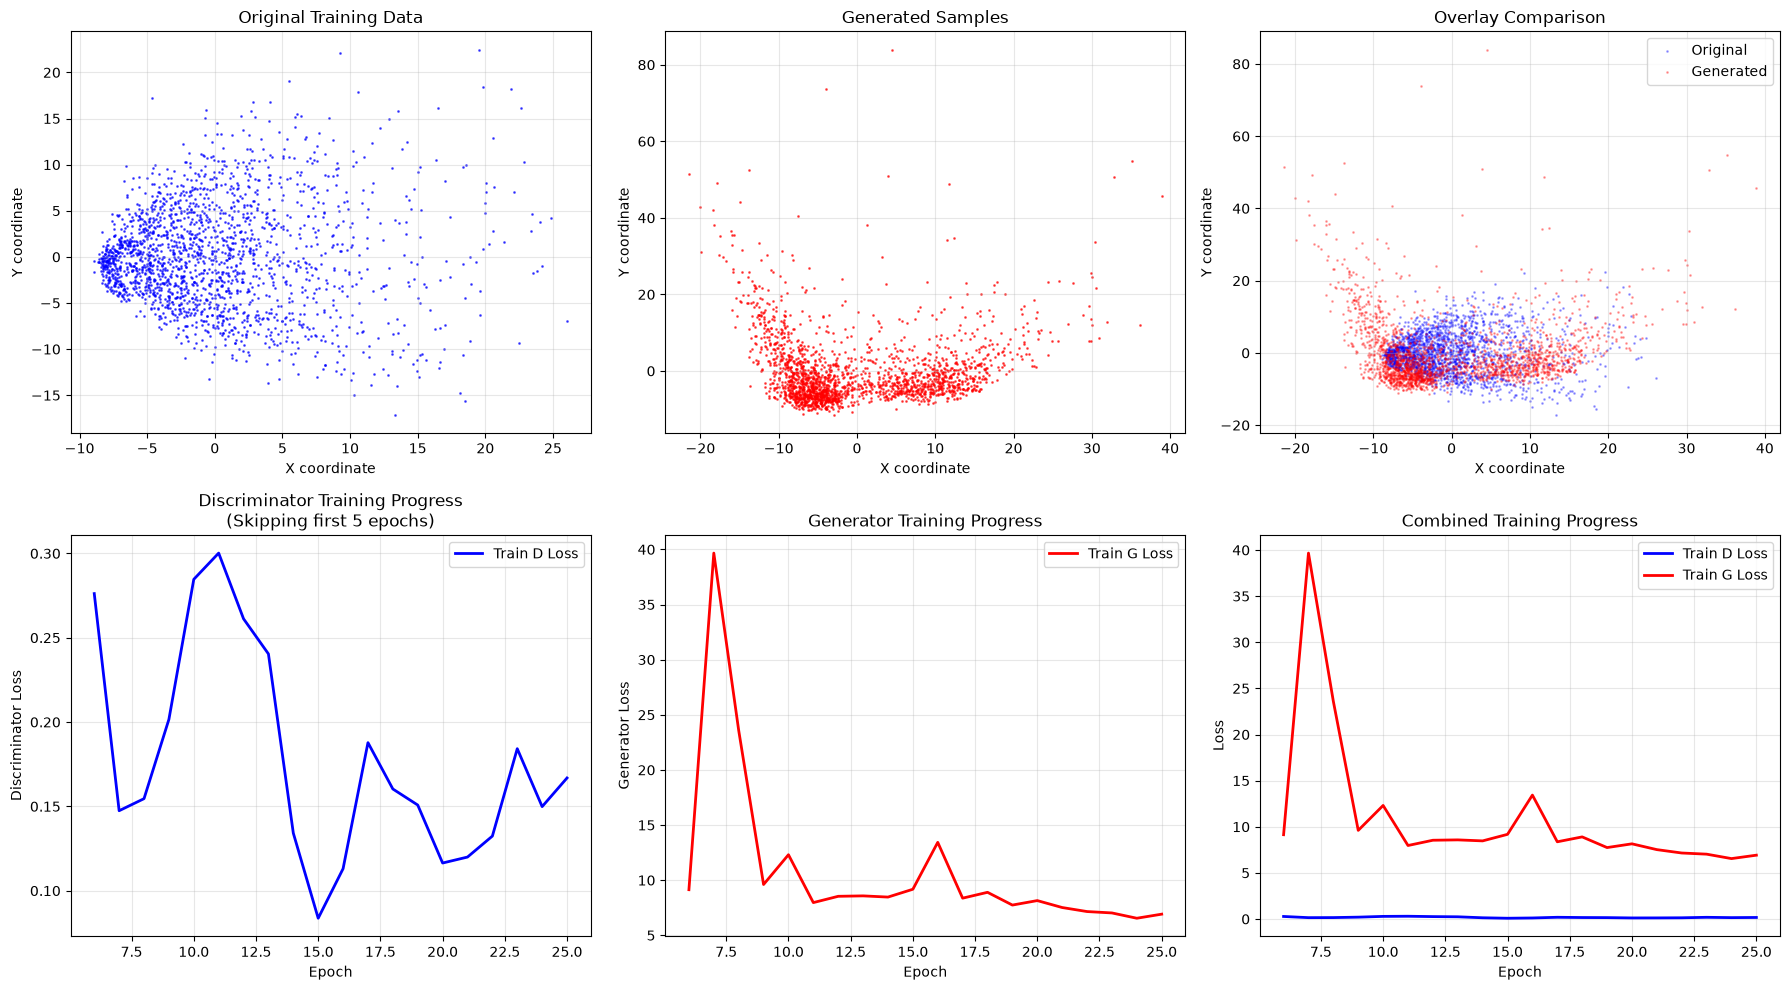

📈 Epoch 25 Summary:
   Train D Loss: 0.1668, Val D Loss: 0.0907
   Train G Loss: 6.9197, Val G Loss: 5.8016

📊 Epoch 26/100
----------------------------------------
Epoch: 26 [0/60000 (0%)]	D_loss: 0.087487	G_loss: 5.200958
Epoch: 26 [6400/60000 (11%)]	D_loss: 0.075536	G_loss: 7.691486
Epoch: 26 [12800/60000 (21%)]	D_loss: 0.073887	G_loss: 7.872519
Epoch: 26 [19200/60000 (32%)]	D_loss: 0.254759	G_loss: 8.815273
Epoch: 26 [25600/60000 (43%)]	D_loss: 0.075851	G_loss: 7.543630
Epoch: 26 [32000/60000 (53%)]	D_loss: 0.106068	G_loss: 7.690225
Epoch: 26 [38400/60000 (64%)]	D_loss: 0.072636	G_loss: 9.266729
Epoch: 26 [44800/60000 (75%)]	D_loss: 0.125023	G_loss: 8.842236
Epoch: 26 [51200/60000 (85%)]	D_loss: 0.146154	G_loss: 5.916384
Epoch: 26 [57600/60000 (96%)]	D_loss: 0.128593	G_loss: 4.964499
====> Epoch: 26 Train D_loss: 0.1628, Train G_loss: 7.3344
====> Epoch: 26 Val D_loss: 0.1111, Val G_loss: 5.6599
📈 Epoch 26 Summary:
   Train D Loss: 0.1628, Val D Loss: 0.1111
   Train G Loss: 7.3344

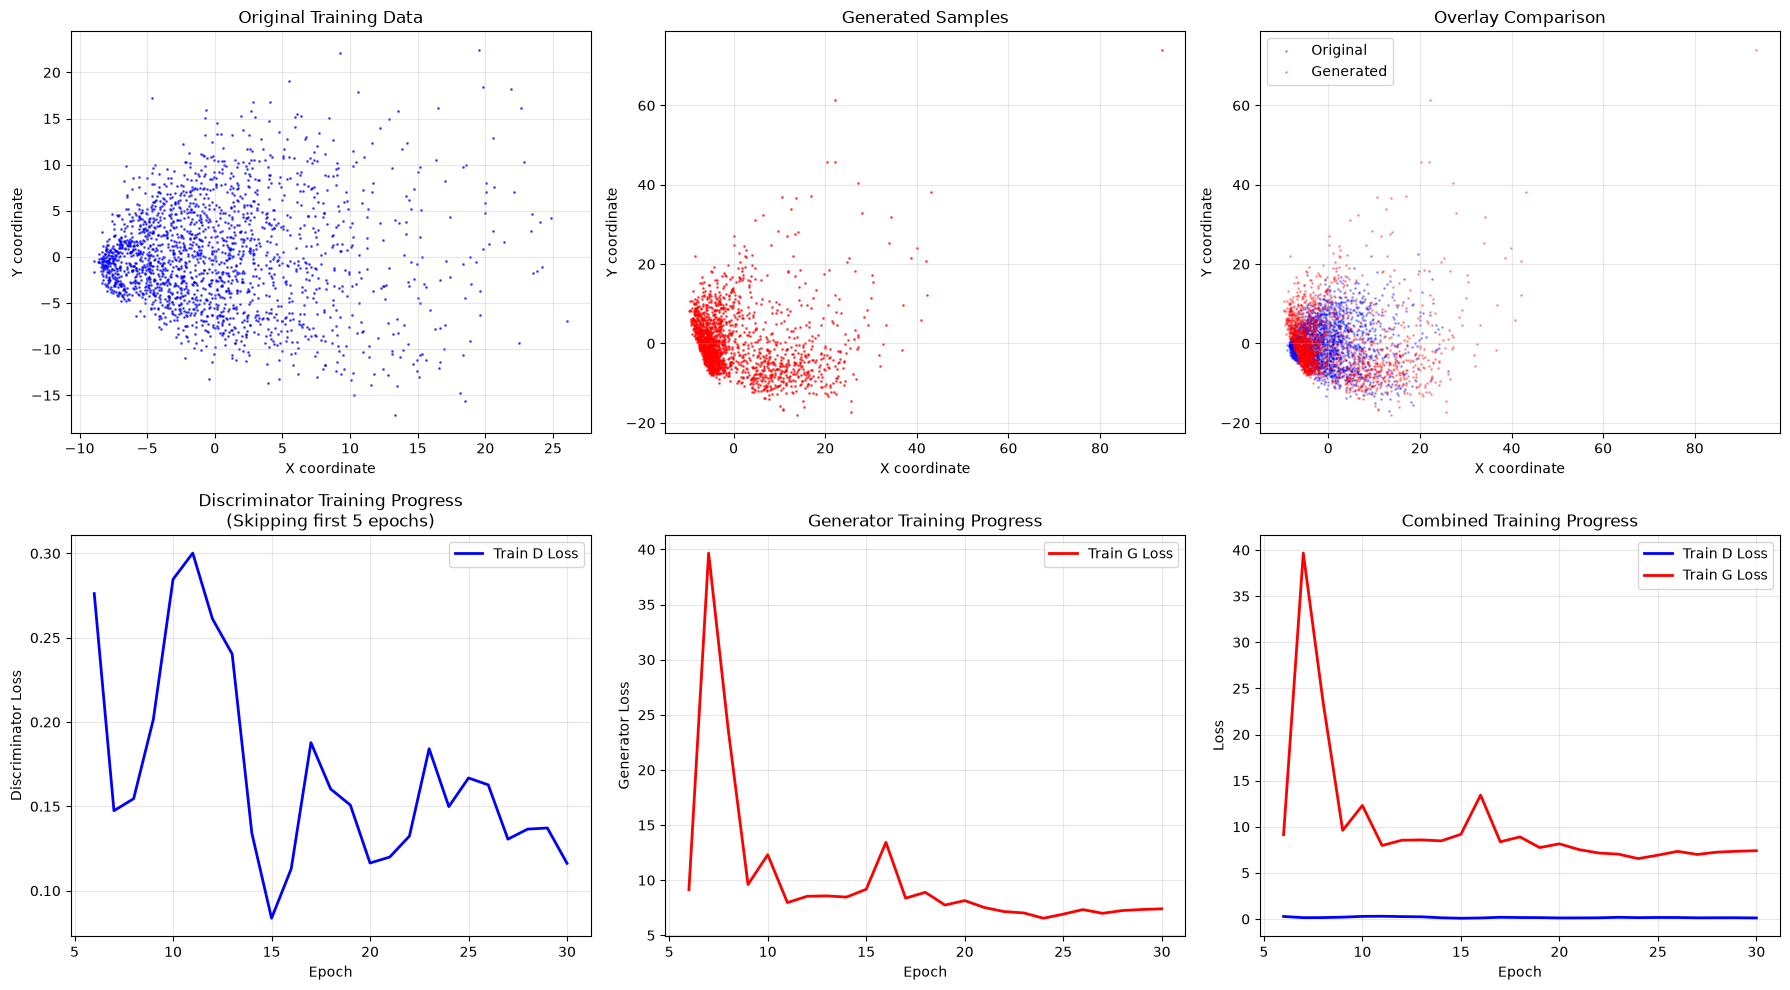

📈 Epoch 30 Summary:
   Train D Loss: 0.1162, Val D Loss: 0.1214
   Train G Loss: 7.4022, Val G Loss: 5.5205

📊 Epoch 31/100
----------------------------------------
Epoch: 31 [0/60000 (0%)]	D_loss: 0.080683	G_loss: 7.566199
Epoch: 31 [6400/60000 (11%)]	D_loss: 0.027342	G_loss: 7.837458
Epoch: 31 [12800/60000 (21%)]	D_loss: 0.280456	G_loss: 8.953411
Epoch: 31 [19200/60000 (32%)]	D_loss: 0.127857	G_loss: 7.811704
Epoch: 31 [25600/60000 (43%)]	D_loss: 0.161852	G_loss: 6.666301
Epoch: 31 [32000/60000 (53%)]	D_loss: 0.265975	G_loss: 6.800828
Epoch: 31 [38400/60000 (64%)]	D_loss: 0.175726	G_loss: 9.027952
Epoch: 31 [44800/60000 (75%)]	D_loss: 0.051038	G_loss: 7.080647
Epoch: 31 [51200/60000 (85%)]	D_loss: 0.052047	G_loss: 6.169396
Epoch: 31 [57600/60000 (96%)]	D_loss: 0.044225	G_loss: 7.464457
====> Epoch: 31 Train D_loss: 0.1053, Train G_loss: 7.5461
====> Epoch: 31 Val D_loss: 0.1927, Val G_loss: 4.8487
📈 Epoch 31 Summary:
   Train D Loss: 0.1053, Val D Loss: 0.1927
   Train G Loss: 7.5461

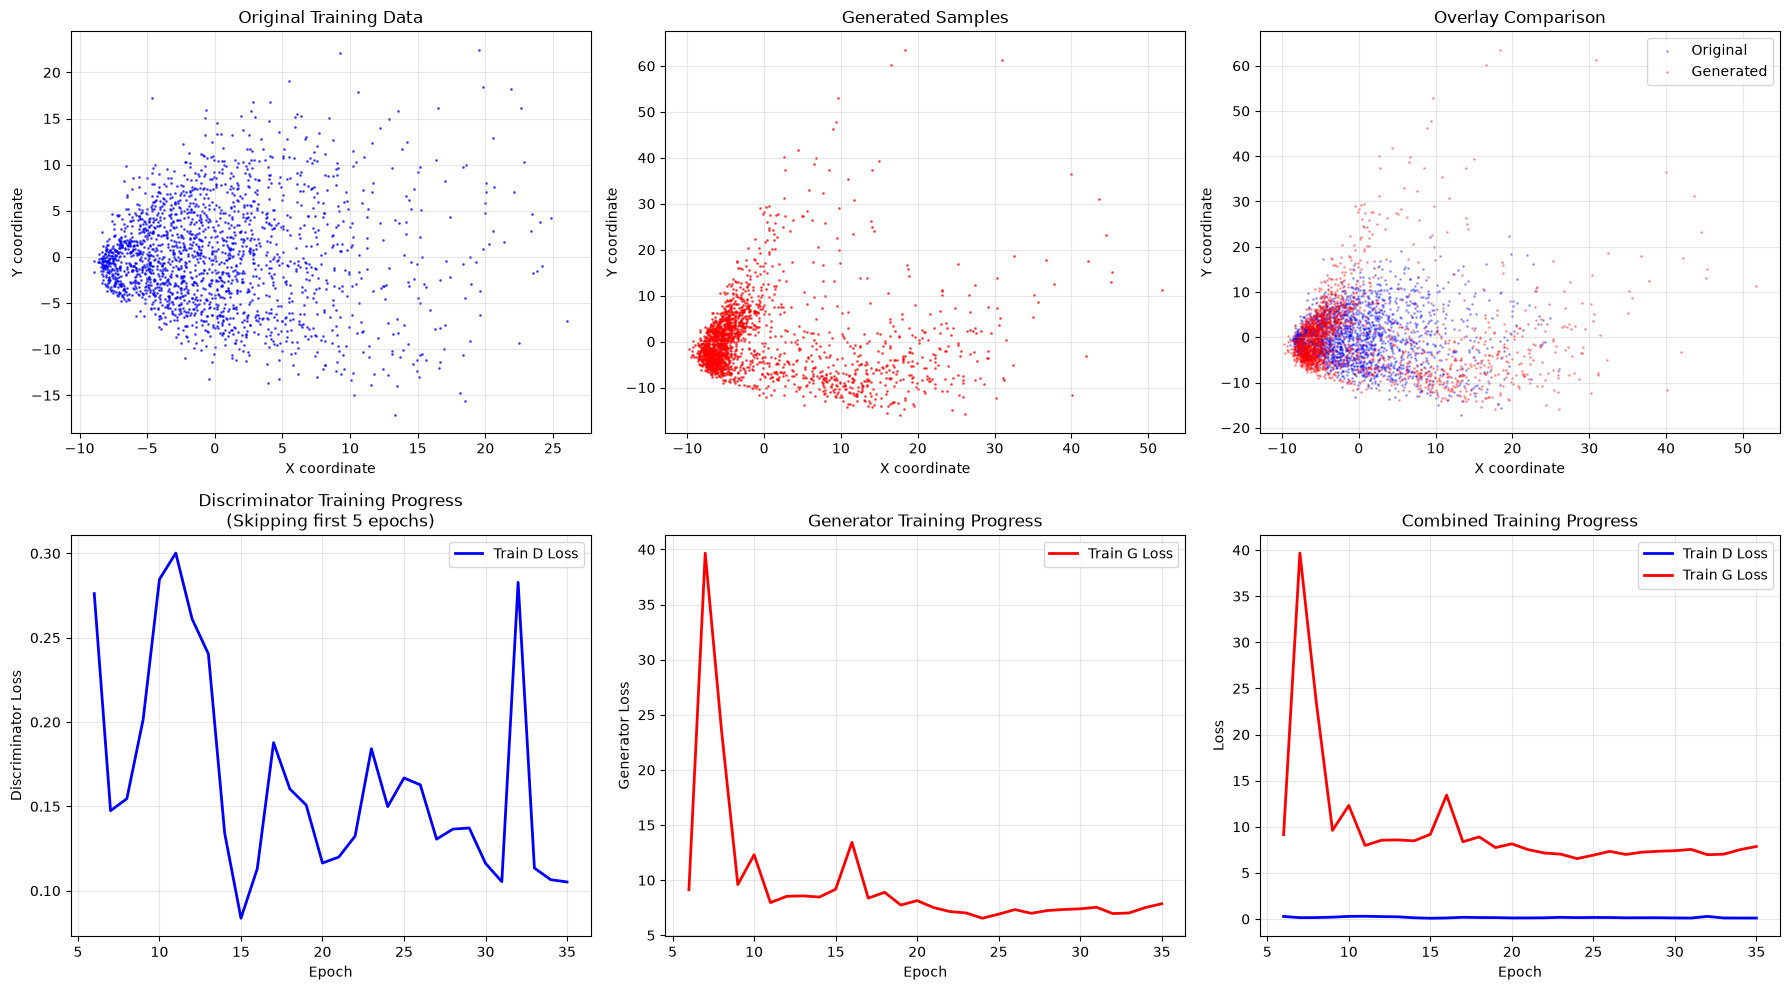

📈 Epoch 35 Summary:
   Train D Loss: 0.1052, Val D Loss: 0.1094
   Train G Loss: 7.8618, Val G Loss: 6.8415

📊 Epoch 36/100
----------------------------------------
Epoch: 36 [0/60000 (0%)]	D_loss: 0.101433	G_loss: 6.295013
Epoch: 36 [6400/60000 (11%)]	D_loss: 0.064136	G_loss: 7.903138
Epoch: 36 [12800/60000 (21%)]	D_loss: 0.158232	G_loss: 6.385825
Epoch: 36 [19200/60000 (32%)]	D_loss: 0.213387	G_loss: 9.435861
Epoch: 36 [25600/60000 (43%)]	D_loss: 0.107682	G_loss: 19.283524
Epoch: 36 [32000/60000 (53%)]	D_loss: 0.086001	G_loss: 7.321491
Epoch: 36 [38400/60000 (64%)]	D_loss: 0.042347	G_loss: 9.769374
Epoch: 36 [44800/60000 (75%)]	D_loss: 0.073439	G_loss: 6.862108
Epoch: 36 [51200/60000 (85%)]	D_loss: 0.026864	G_loss: 7.933945
Epoch: 36 [57600/60000 (96%)]	D_loss: 0.127215	G_loss: 7.104786
====> Epoch: 36 Train D_loss: 0.1052, Train G_loss: 7.6209
====> Epoch: 36 Val D_loss: 0.2239, Val G_loss: 8.5909
📈 Epoch 36 Summary:
   Train D Loss: 0.1052, Val D Loss: 0.2239
   Train G Loss: 7.620

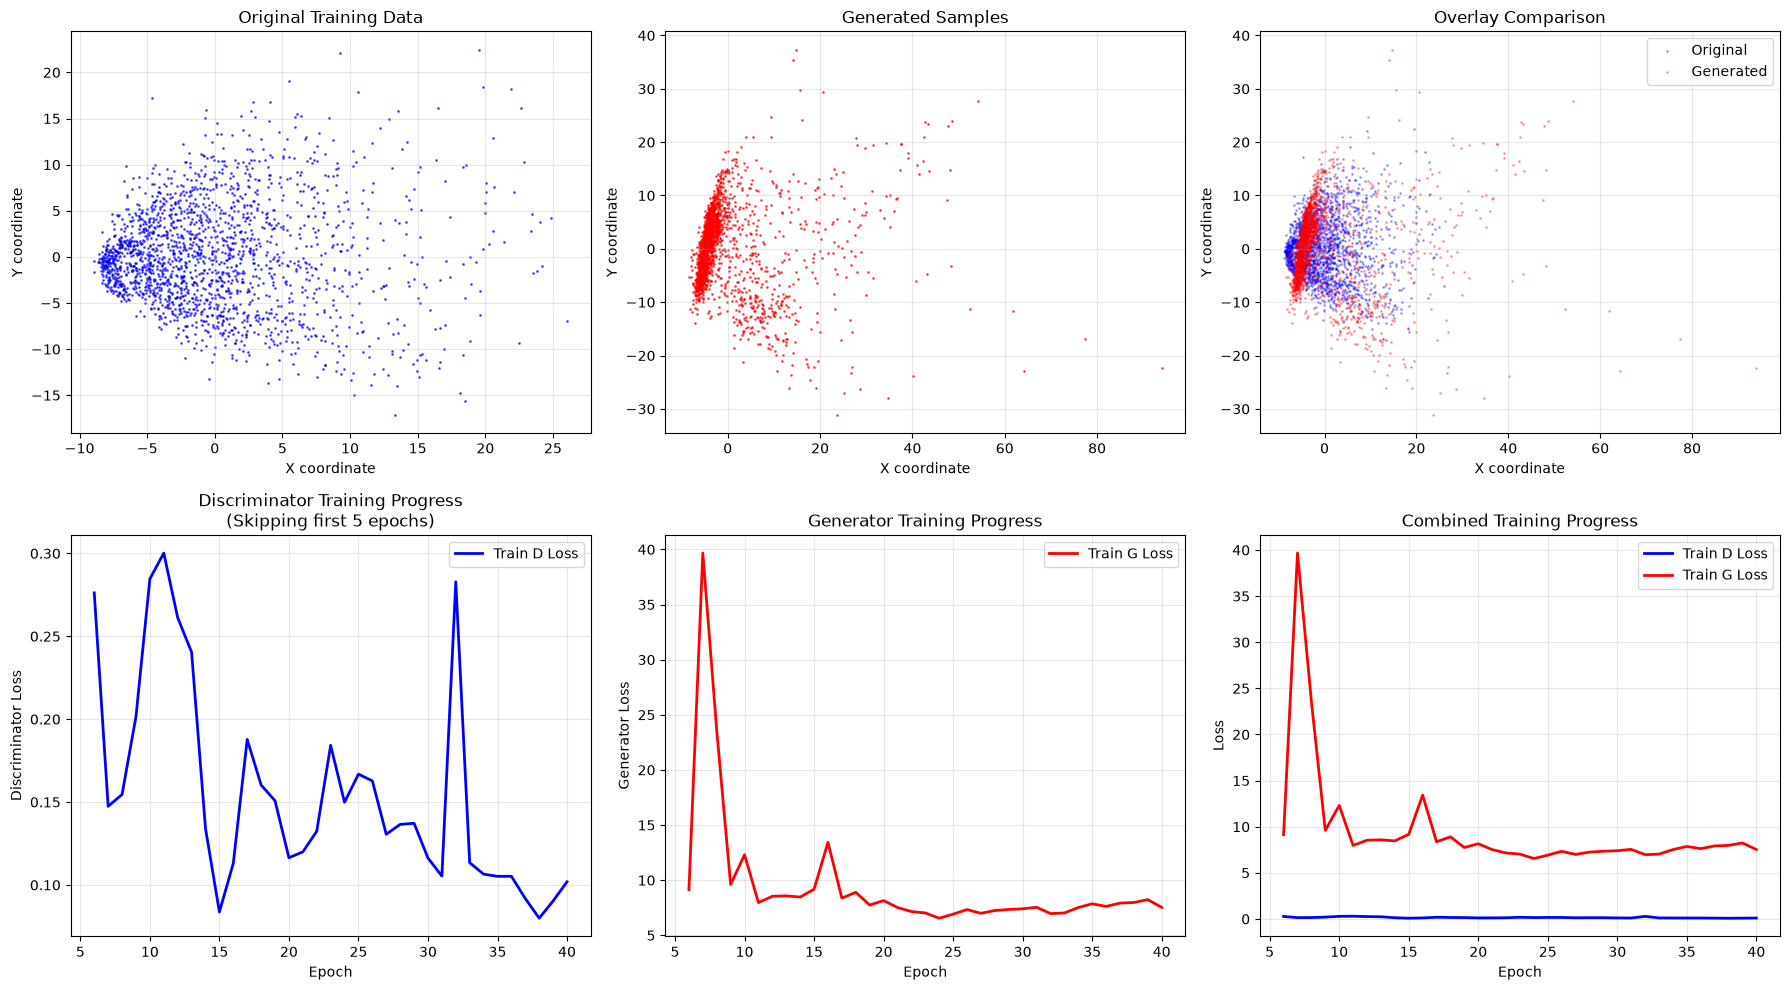

📈 Epoch 40 Summary:
   Train D Loss: 0.1019, Val D Loss: 0.1149
   Train G Loss: 7.5314, Val G Loss: 8.7717

📊 Epoch 41/100
----------------------------------------
Epoch: 41 [0/60000 (0%)]	D_loss: 0.121134	G_loss: 9.322063
Epoch: 41 [6400/60000 (11%)]	D_loss: 0.054270	G_loss: 9.706411
Epoch: 41 [12800/60000 (21%)]	D_loss: 0.038933	G_loss: 8.151618
Epoch: 41 [19200/60000 (32%)]	D_loss: 0.118286	G_loss: 7.702977
Epoch: 41 [25600/60000 (43%)]	D_loss: 0.174600	G_loss: 8.624945
Epoch: 41 [32000/60000 (53%)]	D_loss: 0.097330	G_loss: 8.305683
Epoch: 41 [38400/60000 (64%)]	D_loss: 0.041990	G_loss: 6.835765
Epoch: 41 [44800/60000 (75%)]	D_loss: 0.071834	G_loss: 7.735244
Epoch: 41 [51200/60000 (85%)]	D_loss: 0.078410	G_loss: 9.035563
Epoch: 41 [57600/60000 (96%)]	D_loss: 0.088107	G_loss: 8.770496
====> Epoch: 41 Train D_loss: 0.0772, Train G_loss: 8.0829
====> Epoch: 41 Val D_loss: 0.0351, Val G_loss: 8.5592
📈 Epoch 41 Summary:
   Train D Loss: 0.0772, Val D Loss: 0.0351
   Train G Loss: 8.0829

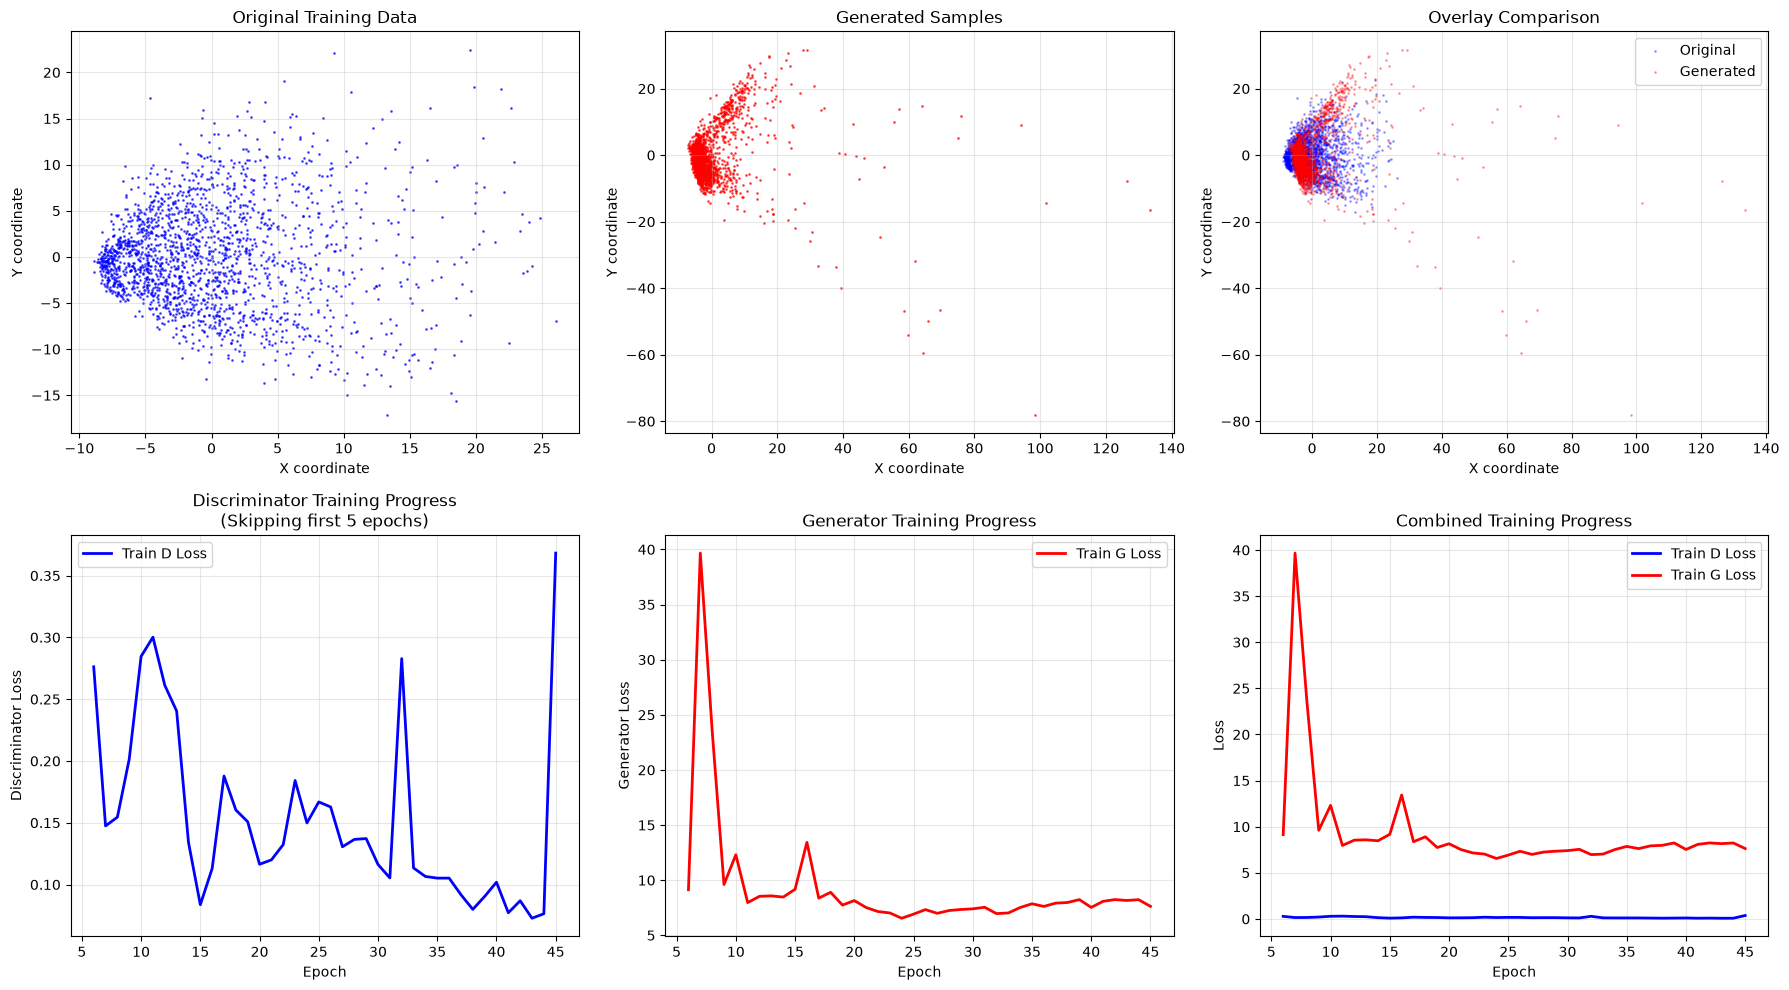

📈 Epoch 45 Summary:
   Train D Loss: 0.3682, Val D Loss: 0.0608
   Train G Loss: 7.6294, Val G Loss: 7.2237

📊 Epoch 46/100
----------------------------------------
Epoch: 46 [0/60000 (0%)]	D_loss: 0.090635	G_loss: 6.312984
Epoch: 46 [6400/60000 (11%)]	D_loss: 0.051202	G_loss: 7.233073
Epoch: 46 [12800/60000 (21%)]	D_loss: 0.055214	G_loss: 6.705051
Epoch: 46 [19200/60000 (32%)]	D_loss: 0.067617	G_loss: 8.125637
Epoch: 46 [25600/60000 (43%)]	D_loss: 0.132766	G_loss: 9.396652
Epoch: 46 [32000/60000 (53%)]	D_loss: 0.036329	G_loss: 7.260210
Epoch: 46 [38400/60000 (64%)]	D_loss: 0.168891	G_loss: 8.229038
Epoch: 46 [44800/60000 (75%)]	D_loss: 0.031356	G_loss: 7.691786
Epoch: 46 [51200/60000 (85%)]	D_loss: 0.180059	G_loss: 8.807583
Epoch: 46 [57600/60000 (96%)]	D_loss: 0.030381	G_loss: 6.839440
====> Epoch: 46 Train D_loss: 0.0751, Train G_loss: 7.2030
====> Epoch: 46 Val D_loss: 0.0876, Val G_loss: 4.7745
📈 Epoch 46 Summary:
   Train D Loss: 0.0751, Val D Loss: 0.0876
   Train G Loss: 7.2030

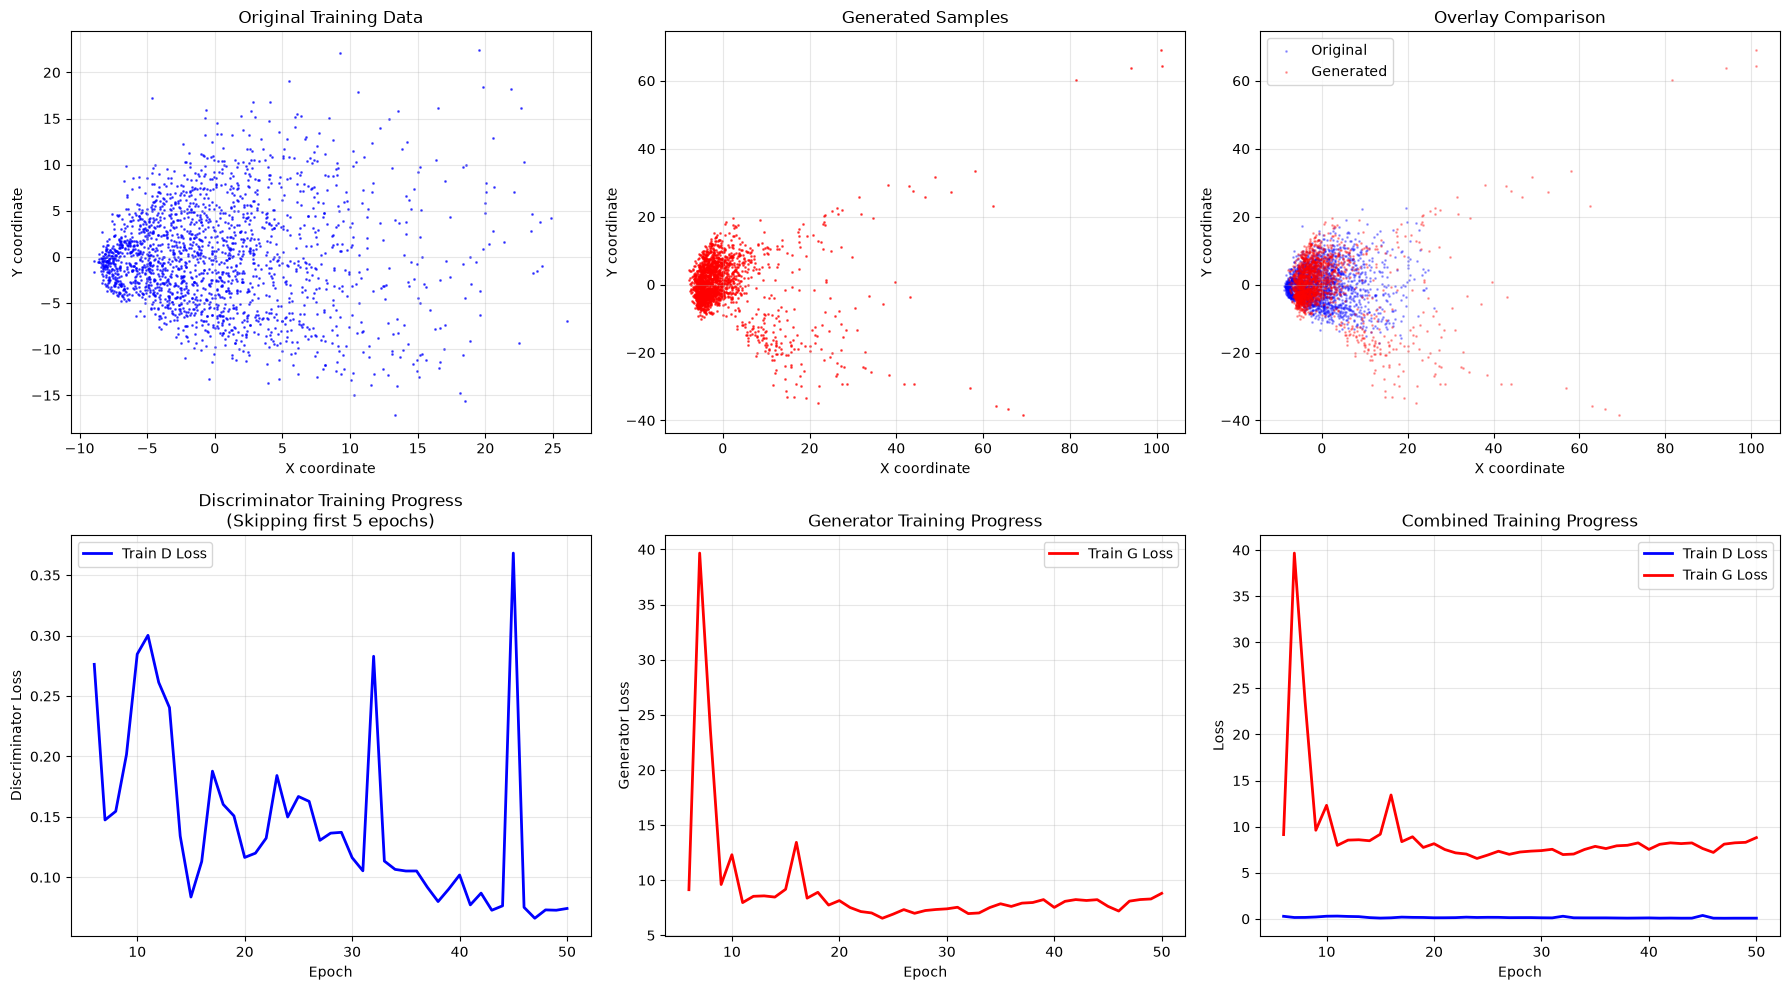

📈 Epoch 50 Summary:
   Train D Loss: 0.0742, Val D Loss: 0.0844
   Train G Loss: 8.8079, Val G Loss: 9.0019

📊 Epoch 51/100
----------------------------------------
Epoch: 51 [0/60000 (0%)]	D_loss: 0.119310	G_loss: 8.682517
Epoch: 51 [6400/60000 (11%)]	D_loss: 0.085685	G_loss: 7.856428
Epoch: 51 [12800/60000 (21%)]	D_loss: 0.020560	G_loss: 6.562428
Epoch: 51 [19200/60000 (32%)]	D_loss: 0.009348	G_loss: 7.172613
Epoch: 51 [25600/60000 (43%)]	D_loss: 0.043433	G_loss: 6.982777
Epoch: 51 [32000/60000 (53%)]	D_loss: 0.021100	G_loss: 9.876621
Epoch: 51 [38400/60000 (64%)]	D_loss: 0.021280	G_loss: 8.143751
Epoch: 51 [44800/60000 (75%)]	D_loss: 0.112651	G_loss: 7.461584
Epoch: 51 [51200/60000 (85%)]	D_loss: 0.035561	G_loss: 7.855300
Epoch: 51 [57600/60000 (96%)]	D_loss: 0.381578	G_loss: 13.859915
====> Epoch: 51 Train D_loss: 0.0639, Train G_loss: 8.2774
====> Epoch: 51 Val D_loss: 0.1242, Val G_loss: 8.4788
📈 Epoch 51 Summary:
   Train D Loss: 0.0639, Val D Loss: 0.1242
   Train G Loss: 8.277

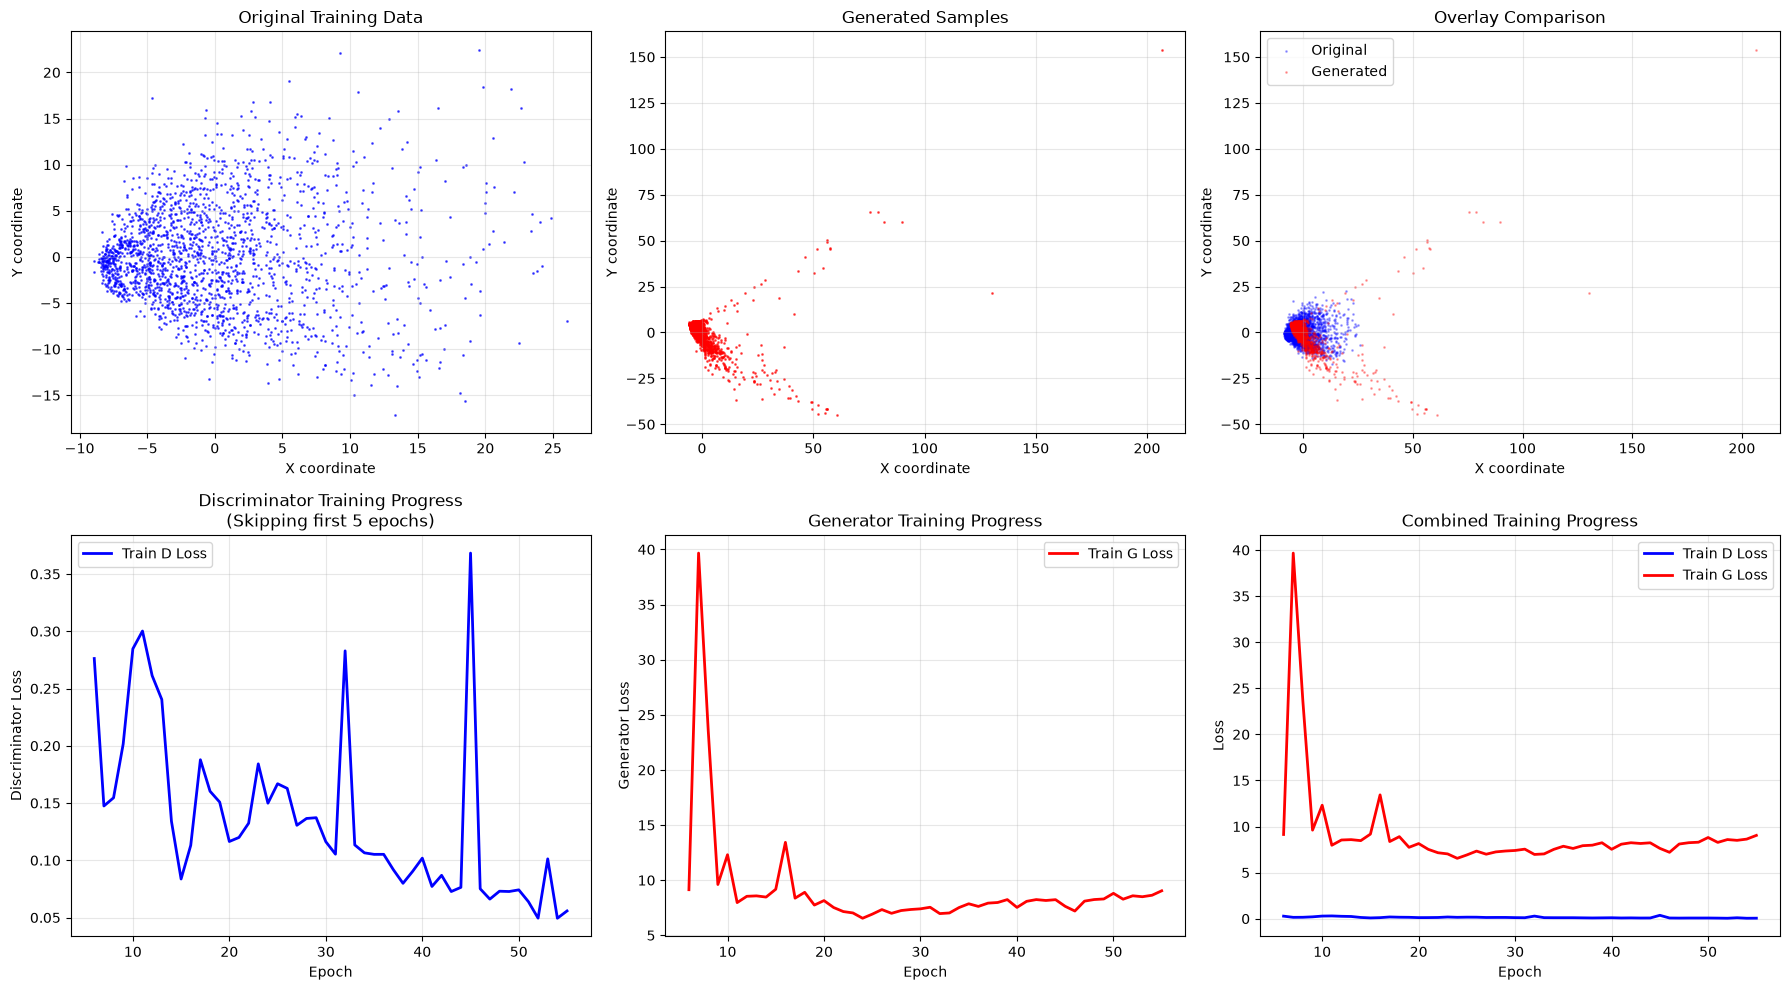

📈 Epoch 55 Summary:
   Train D Loss: 0.0558, Val D Loss: 0.0577
   Train G Loss: 9.0388, Val G Loss: 6.8642

📊 Epoch 56/100
----------------------------------------
Epoch: 56 [0/60000 (0%)]	D_loss: 0.072841	G_loss: 8.228397
Epoch: 56 [6400/60000 (11%)]	D_loss: 0.048026	G_loss: 6.355048
Epoch: 56 [12800/60000 (21%)]	D_loss: 0.021567	G_loss: 8.630533
Epoch: 56 [19200/60000 (32%)]	D_loss: 0.057885	G_loss: 10.267816
Epoch: 56 [25600/60000 (43%)]	D_loss: 0.046495	G_loss: 13.594519
Epoch: 56 [32000/60000 (53%)]	D_loss: 0.016184	G_loss: 9.607049
Epoch: 56 [38400/60000 (64%)]	D_loss: 0.022065	G_loss: 8.154333
Epoch: 56 [44800/60000 (75%)]	D_loss: 0.317167	G_loss: 21.585695
Epoch: 56 [51200/60000 (85%)]	D_loss: 0.128577	G_loss: 7.182367
Epoch: 56 [57600/60000 (96%)]	D_loss: 0.077497	G_loss: 7.678922
====> Epoch: 56 Train D_loss: 0.0760, Train G_loss: 8.6827
====> Epoch: 56 Val D_loss: 0.0603, Val G_loss: 5.2489
📈 Epoch 56 Summary:
   Train D Loss: 0.0760, Val D Loss: 0.0603
   Train G Loss: 8.6

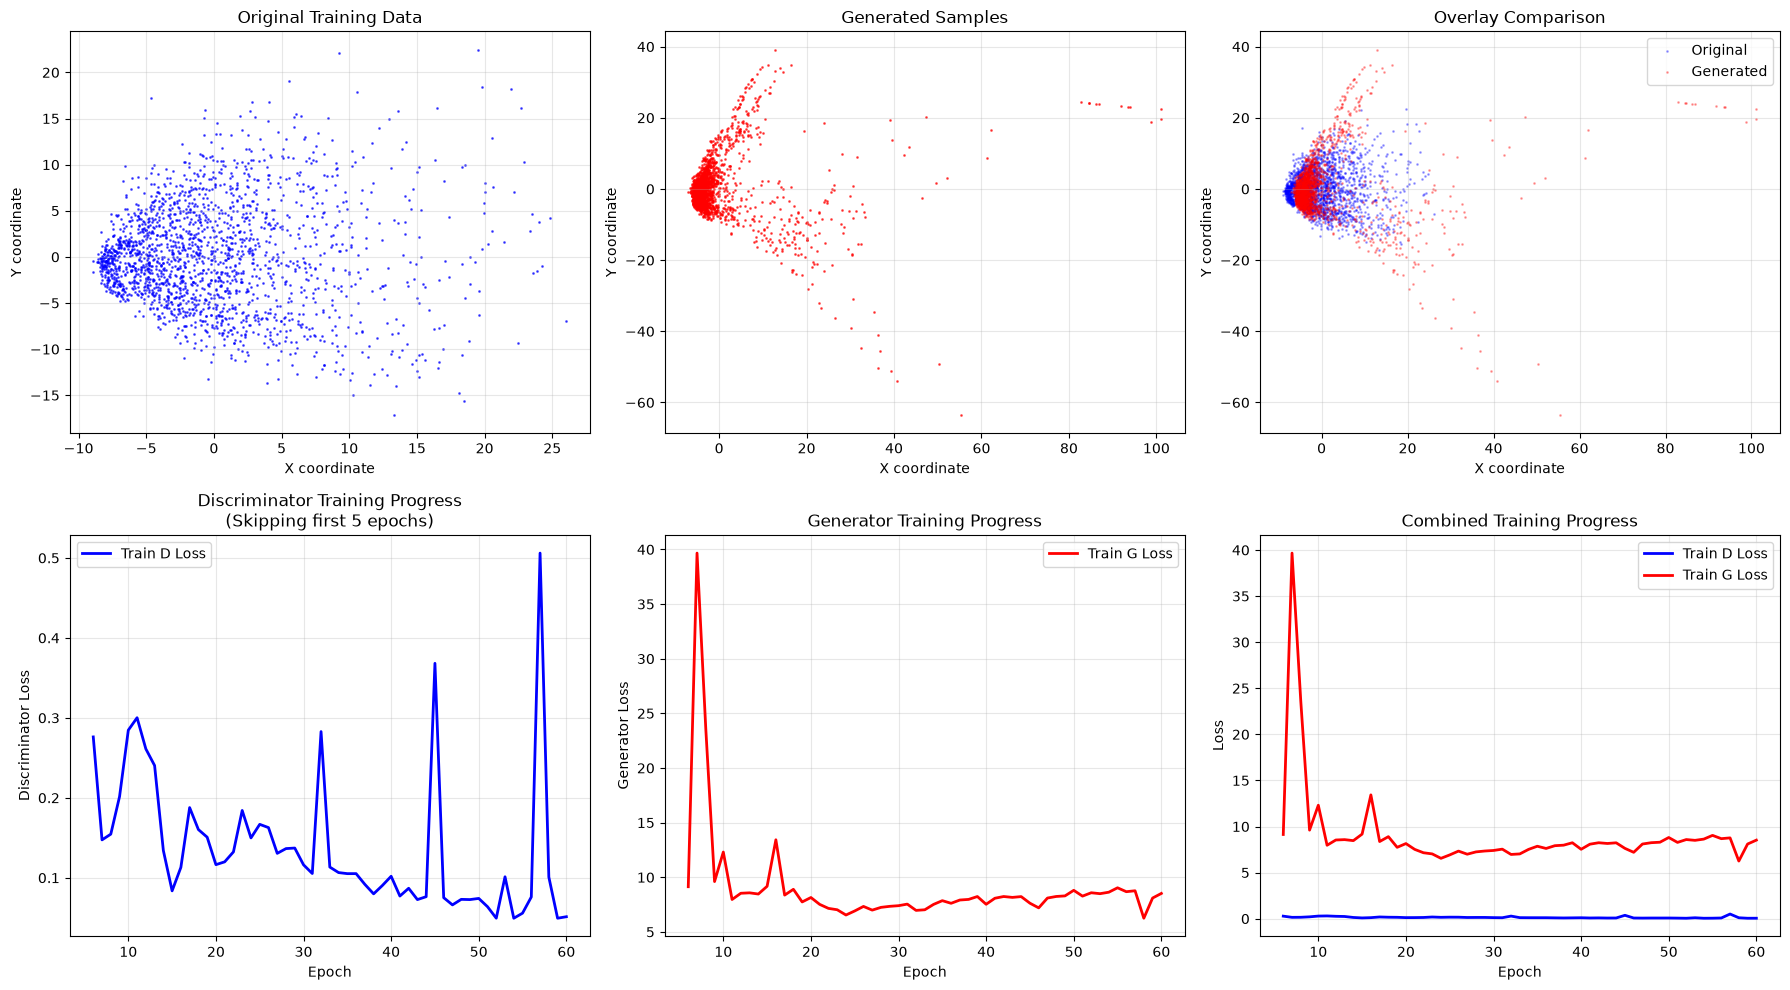

📈 Epoch 60 Summary:
   Train D Loss: 0.0513, Val D Loss: 0.0583
   Train G Loss: 8.5239, Val G Loss: 9.8856

📊 Epoch 61/100
----------------------------------------
Epoch: 61 [0/60000 (0%)]	D_loss: 0.031256	G_loss: 8.700562
Epoch: 61 [6400/60000 (11%)]	D_loss: 0.062071	G_loss: 5.453664
Epoch: 61 [12800/60000 (21%)]	D_loss: 0.107010	G_loss: 13.468412
Epoch: 61 [19200/60000 (32%)]	D_loss: 0.026353	G_loss: 8.506863
Epoch: 61 [25600/60000 (43%)]	D_loss: 0.138781	G_loss: 9.369039
Epoch: 61 [32000/60000 (53%)]	D_loss: 0.041514	G_loss: 7.128154
Epoch: 61 [38400/60000 (64%)]	D_loss: 0.075788	G_loss: 10.524557
Epoch: 61 [44800/60000 (75%)]	D_loss: 0.025650	G_loss: 10.630143
Epoch: 61 [51200/60000 (85%)]	D_loss: 0.049587	G_loss: 8.189795
Epoch: 61 [57600/60000 (96%)]	D_loss: 0.015799	G_loss: 8.246705
====> Epoch: 61 Train D_loss: 0.0542, Train G_loss: 8.6932
====> Epoch: 61 Val D_loss: 0.2209, Val G_loss: 13.3475
📈 Epoch 61 Summary:
   Train D Loss: 0.0542, Val D Loss: 0.2209
   Train G Loss: 8.

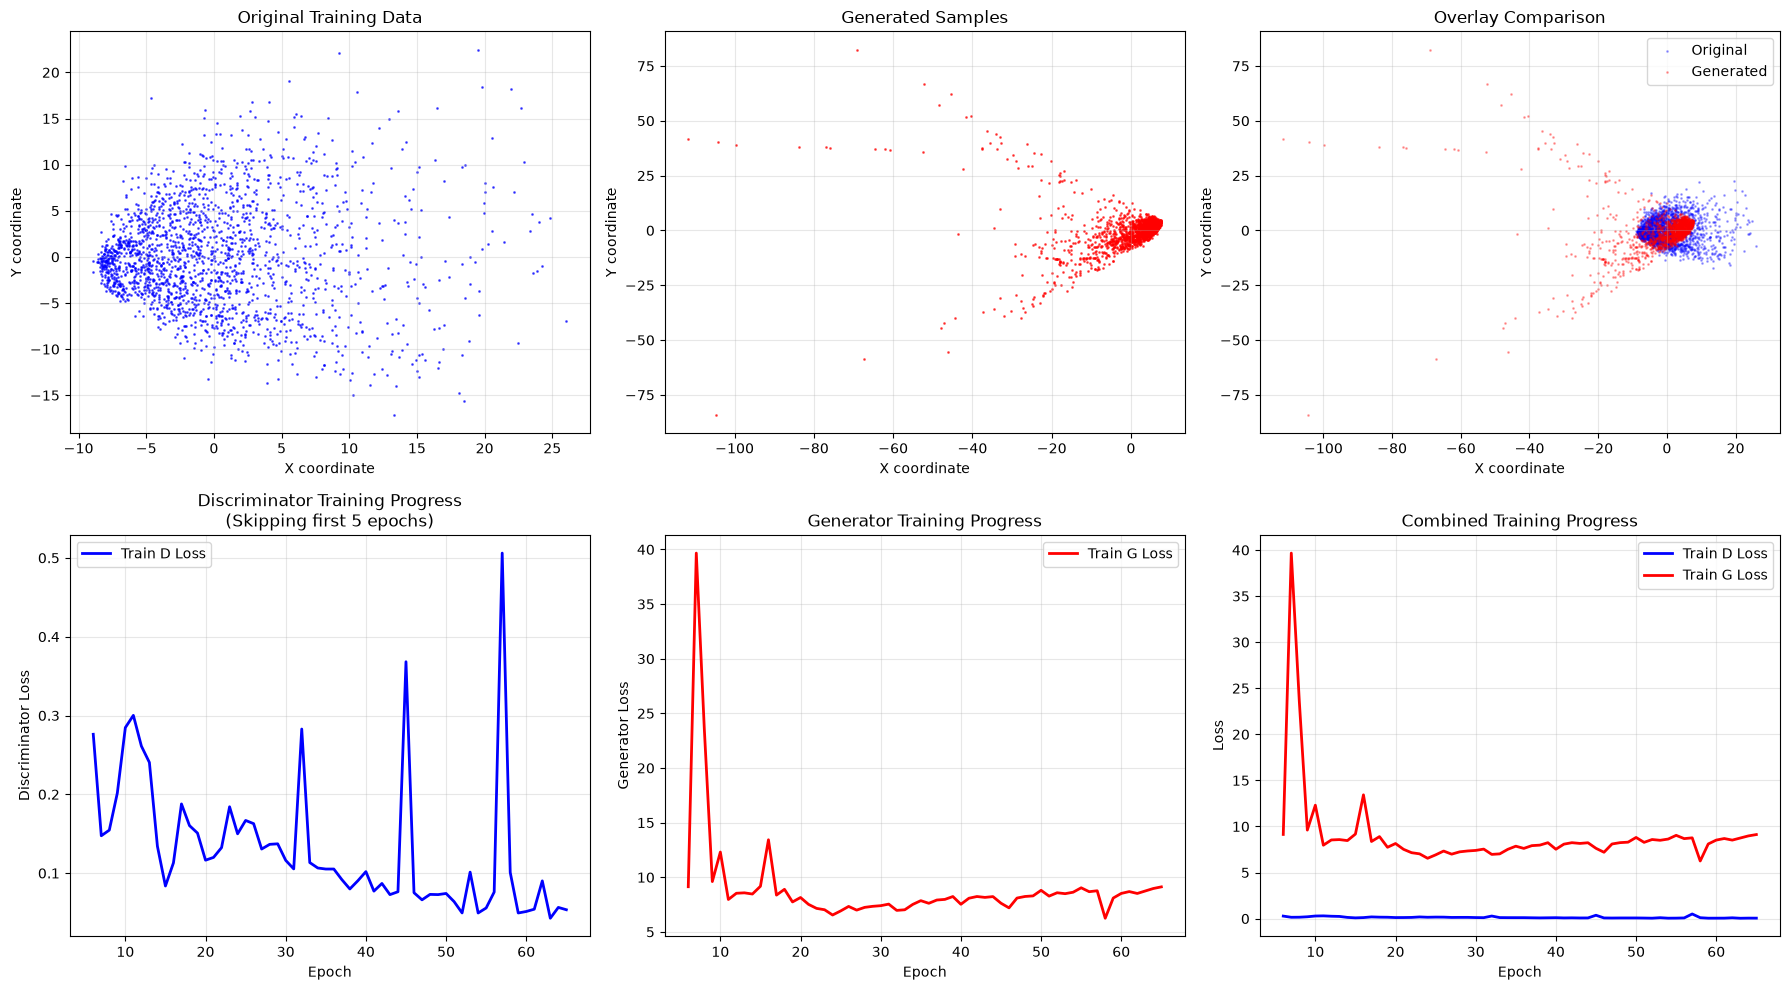

📈 Epoch 65 Summary:
   Train D Loss: 0.0535, Val D Loss: 0.1014
   Train G Loss: 9.1237, Val G Loss: 9.0596

📊 Epoch 66/100
----------------------------------------
Epoch: 66 [0/60000 (0%)]	D_loss: 0.099218	G_loss: 10.172098
Epoch: 66 [6400/60000 (11%)]	D_loss: 0.021473	G_loss: 8.143846
Epoch: 66 [12800/60000 (21%)]	D_loss: 0.038707	G_loss: 8.338741
Epoch: 66 [19200/60000 (32%)]	D_loss: 0.082143	G_loss: 5.254925
Epoch: 66 [25600/60000 (43%)]	D_loss: 0.015596	G_loss: 8.088458
Epoch: 66 [32000/60000 (53%)]	D_loss: 0.052376	G_loss: 8.238482
Epoch: 66 [38400/60000 (64%)]	D_loss: 0.008322	G_loss: 8.888628
Epoch: 66 [44800/60000 (75%)]	D_loss: 0.036658	G_loss: 11.971646
Epoch: 66 [51200/60000 (85%)]	D_loss: 0.069384	G_loss: 7.021703
Epoch: 66 [57600/60000 (96%)]	D_loss: 0.018384	G_loss: 8.549832
====> Epoch: 66 Train D_loss: 0.0451, Train G_loss: 9.1282
====> Epoch: 66 Val D_loss: 0.0849, Val G_loss: 5.0877
📈 Epoch 66 Summary:
   Train D Loss: 0.0451, Val D Loss: 0.0849
   Train G Loss: 9.12

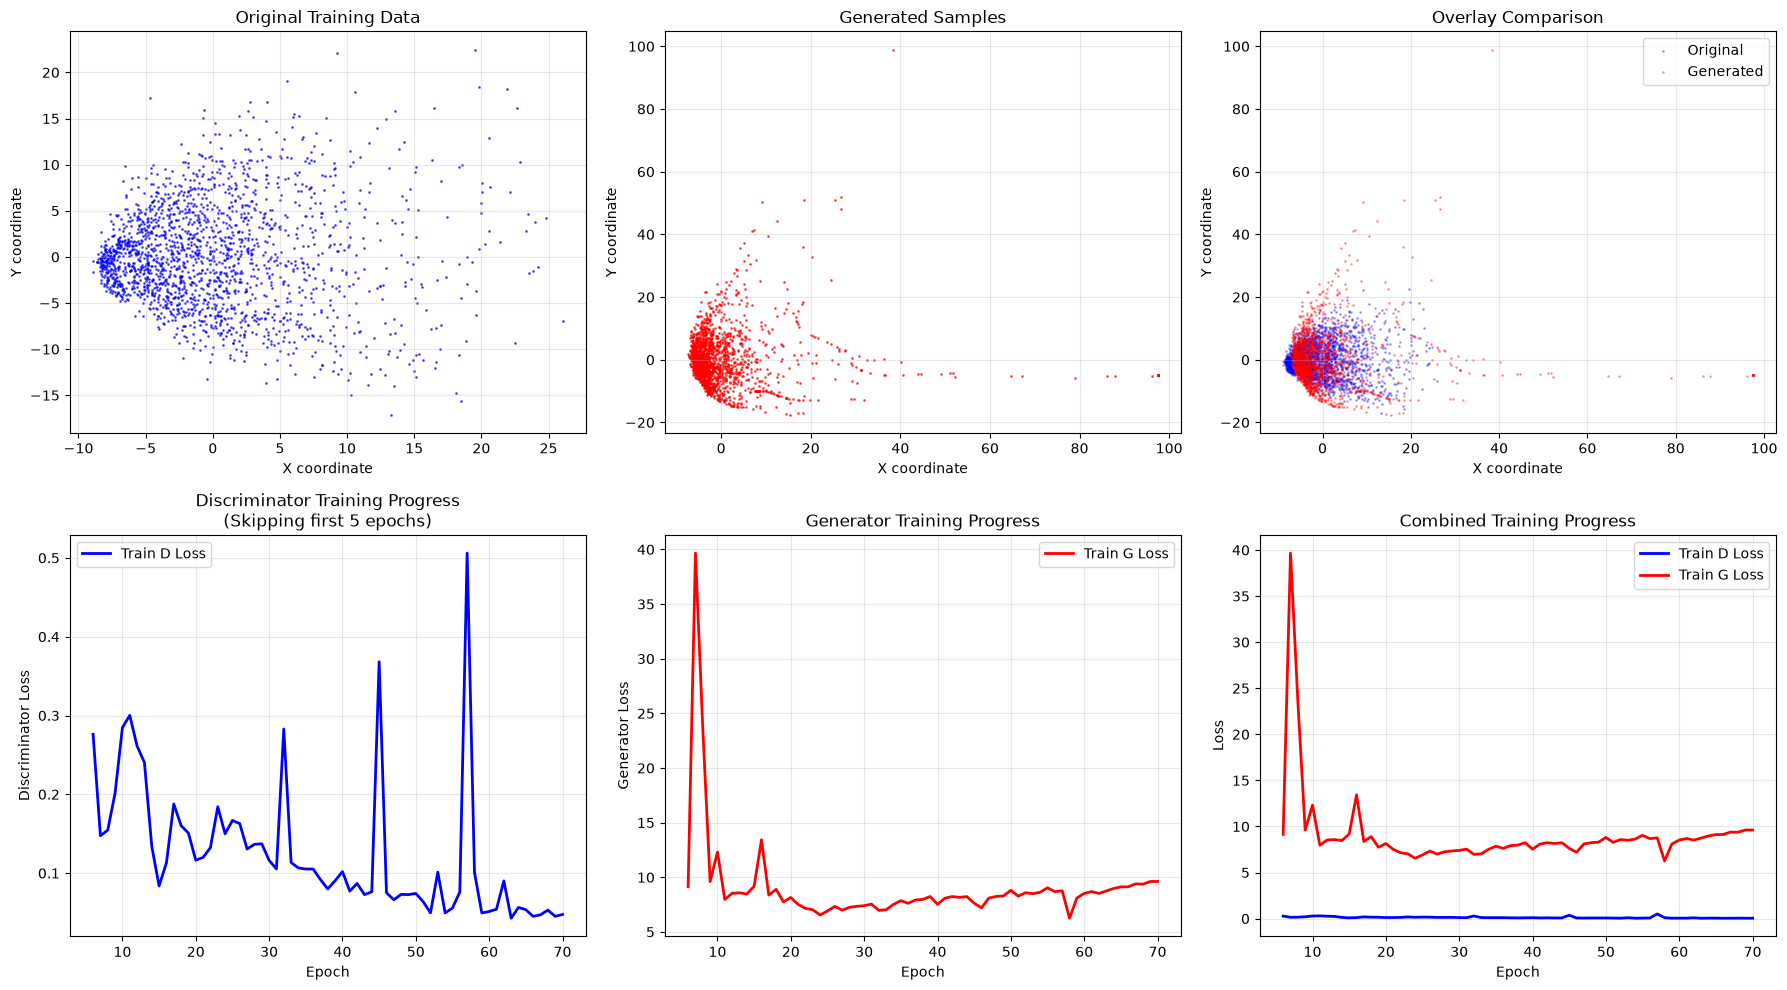

📈 Epoch 70 Summary:
   Train D Loss: 0.0475, Val D Loss: 0.0593
   Train G Loss: 9.6160, Val G Loss: 15.8396

📊 Epoch 71/100
----------------------------------------
Epoch: 71 [0/60000 (0%)]	D_loss: 0.018396	G_loss: 14.827606
Epoch: 71 [6400/60000 (11%)]	D_loss: 0.010989	G_loss: 7.787195
Epoch: 71 [12800/60000 (21%)]	D_loss: 0.044691	G_loss: 7.435112
Epoch: 71 [19200/60000 (32%)]	D_loss: 0.023978	G_loss: 10.023064
Epoch: 71 [25600/60000 (43%)]	D_loss: 0.012248	G_loss: 7.866910
Epoch: 71 [32000/60000 (53%)]	D_loss: 0.020502	G_loss: 6.526340
Epoch: 71 [38400/60000 (64%)]	D_loss: 0.017278	G_loss: 8.153282
Epoch: 71 [44800/60000 (75%)]	D_loss: 0.046436	G_loss: 6.613130
Epoch: 71 [51200/60000 (85%)]	D_loss: 0.057108	G_loss: 11.834087
Epoch: 71 [57600/60000 (96%)]	D_loss: 0.065162	G_loss: 8.303993
====> Epoch: 71 Train D_loss: 0.0488, Train G_loss: 9.1551
====> Epoch: 71 Val D_loss: 0.2264, Val G_loss: 4.6714
📈 Epoch 71 Summary:
   Train D Loss: 0.0488, Val D Loss: 0.2264
   Train G Loss: 9.

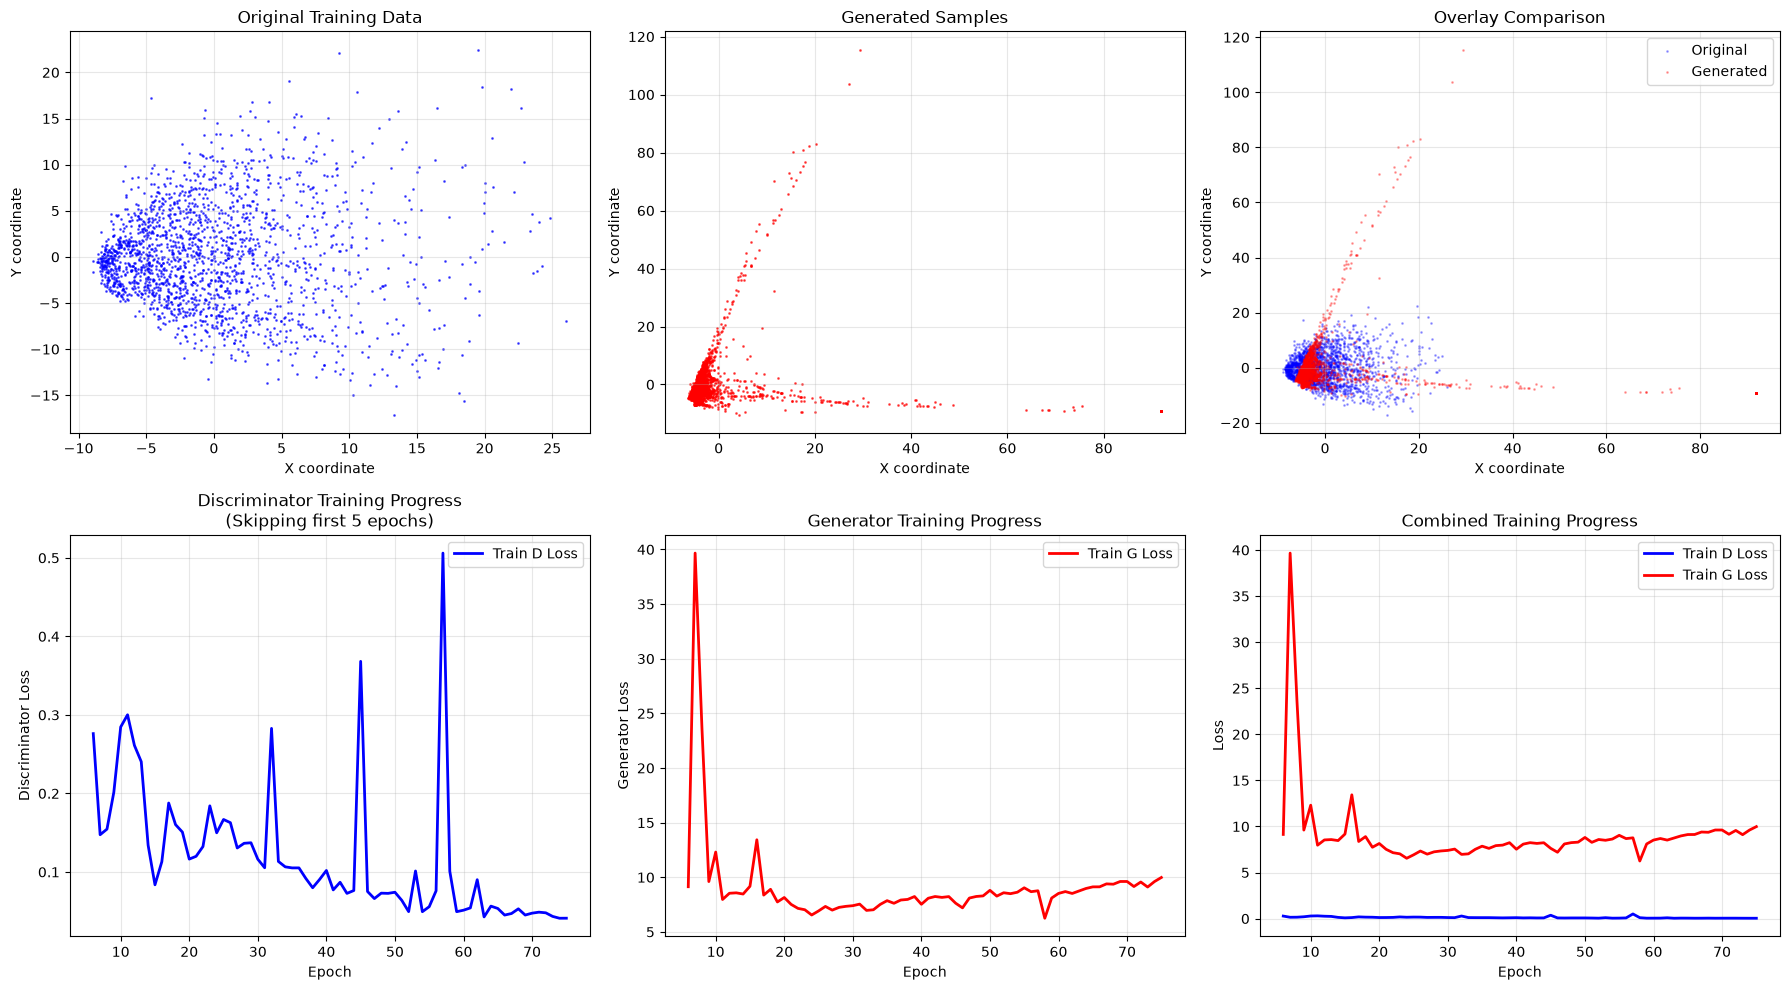

📈 Epoch 75 Summary:
   Train D Loss: 0.0411, Val D Loss: 0.0357
   Train G Loss: 9.9824, Val G Loss: 9.6437

📊 Epoch 76/100
----------------------------------------
Epoch: 76 [0/60000 (0%)]	D_loss: 0.005185	G_loss: 9.870008
Epoch: 76 [6400/60000 (11%)]	D_loss: 0.028582	G_loss: 10.755818
Epoch: 76 [12800/60000 (21%)]	D_loss: 0.054747	G_loss: 7.590569
Epoch: 76 [19200/60000 (32%)]	D_loss: 0.020852	G_loss: 9.113798
Epoch: 76 [25600/60000 (43%)]	D_loss: 0.057209	G_loss: 9.257331
Epoch: 76 [32000/60000 (53%)]	D_loss: 0.004730	G_loss: 8.670269
Epoch: 76 [38400/60000 (64%)]	D_loss: 0.046972	G_loss: 7.866588
Epoch: 76 [44800/60000 (75%)]	D_loss: 0.018787	G_loss: 9.734159
Epoch: 76 [51200/60000 (85%)]	D_loss: 0.030979	G_loss: 8.710833
Epoch: 76 [57600/60000 (96%)]	D_loss: 0.044266	G_loss: 7.469125
====> Epoch: 76 Train D_loss: 0.0408, Train G_loss: 9.8532
====> Epoch: 76 Val D_loss: 0.0527, Val G_loss: 6.9965
📈 Epoch 76 Summary:
   Train D Loss: 0.0408, Val D Loss: 0.0527
   Train G Loss: 9.853

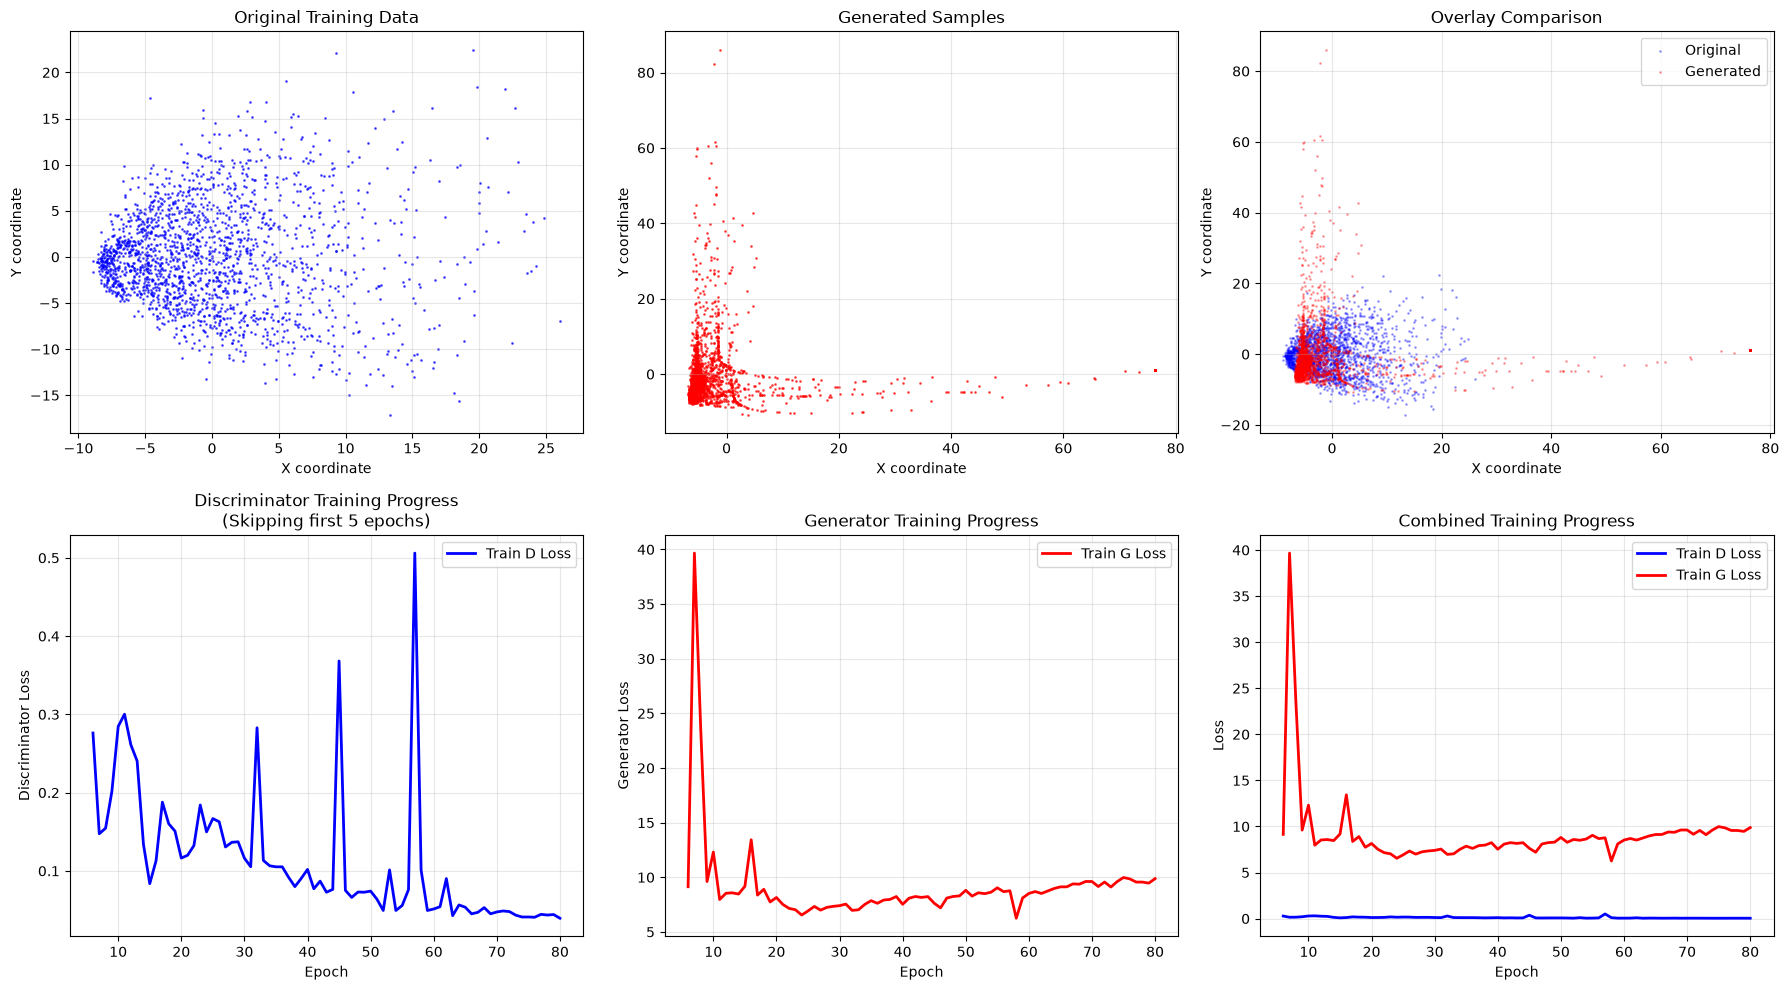

📈 Epoch 80 Summary:
   Train D Loss: 0.0395, Val D Loss: 0.0405
   Train G Loss: 9.8759, Val G Loss: 9.0887

📊 Epoch 81/100
----------------------------------------
Epoch: 81 [0/60000 (0%)]	D_loss: 0.028585	G_loss: 8.314516
Epoch: 81 [6400/60000 (11%)]	D_loss: 0.022653	G_loss: 7.162194
Epoch: 81 [12800/60000 (21%)]	D_loss: 0.042355	G_loss: 7.973048
Epoch: 81 [19200/60000 (32%)]	D_loss: 0.189818	G_loss: 8.839199
Epoch: 81 [25600/60000 (43%)]	D_loss: 0.021991	G_loss: 10.957550
Epoch: 81 [32000/60000 (53%)]	D_loss: 0.006896	G_loss: 7.644978
Epoch: 81 [38400/60000 (64%)]	D_loss: 0.033983	G_loss: 10.403469
Epoch: 81 [44800/60000 (75%)]	D_loss: 0.025503	G_loss: 12.150379
Epoch: 81 [51200/60000 (85%)]	D_loss: 0.029494	G_loss: 8.529184
Epoch: 81 [57600/60000 (96%)]	D_loss: 0.016827	G_loss: 7.823777
====> Epoch: 81 Train D_loss: 0.0408, Train G_loss: 9.6768
====> Epoch: 81 Val D_loss: 0.0894, Val G_loss: 9.1547
📈 Epoch 81 Summary:
   Train D Loss: 0.0408, Val D Loss: 0.0894
   Train G Loss: 9.6

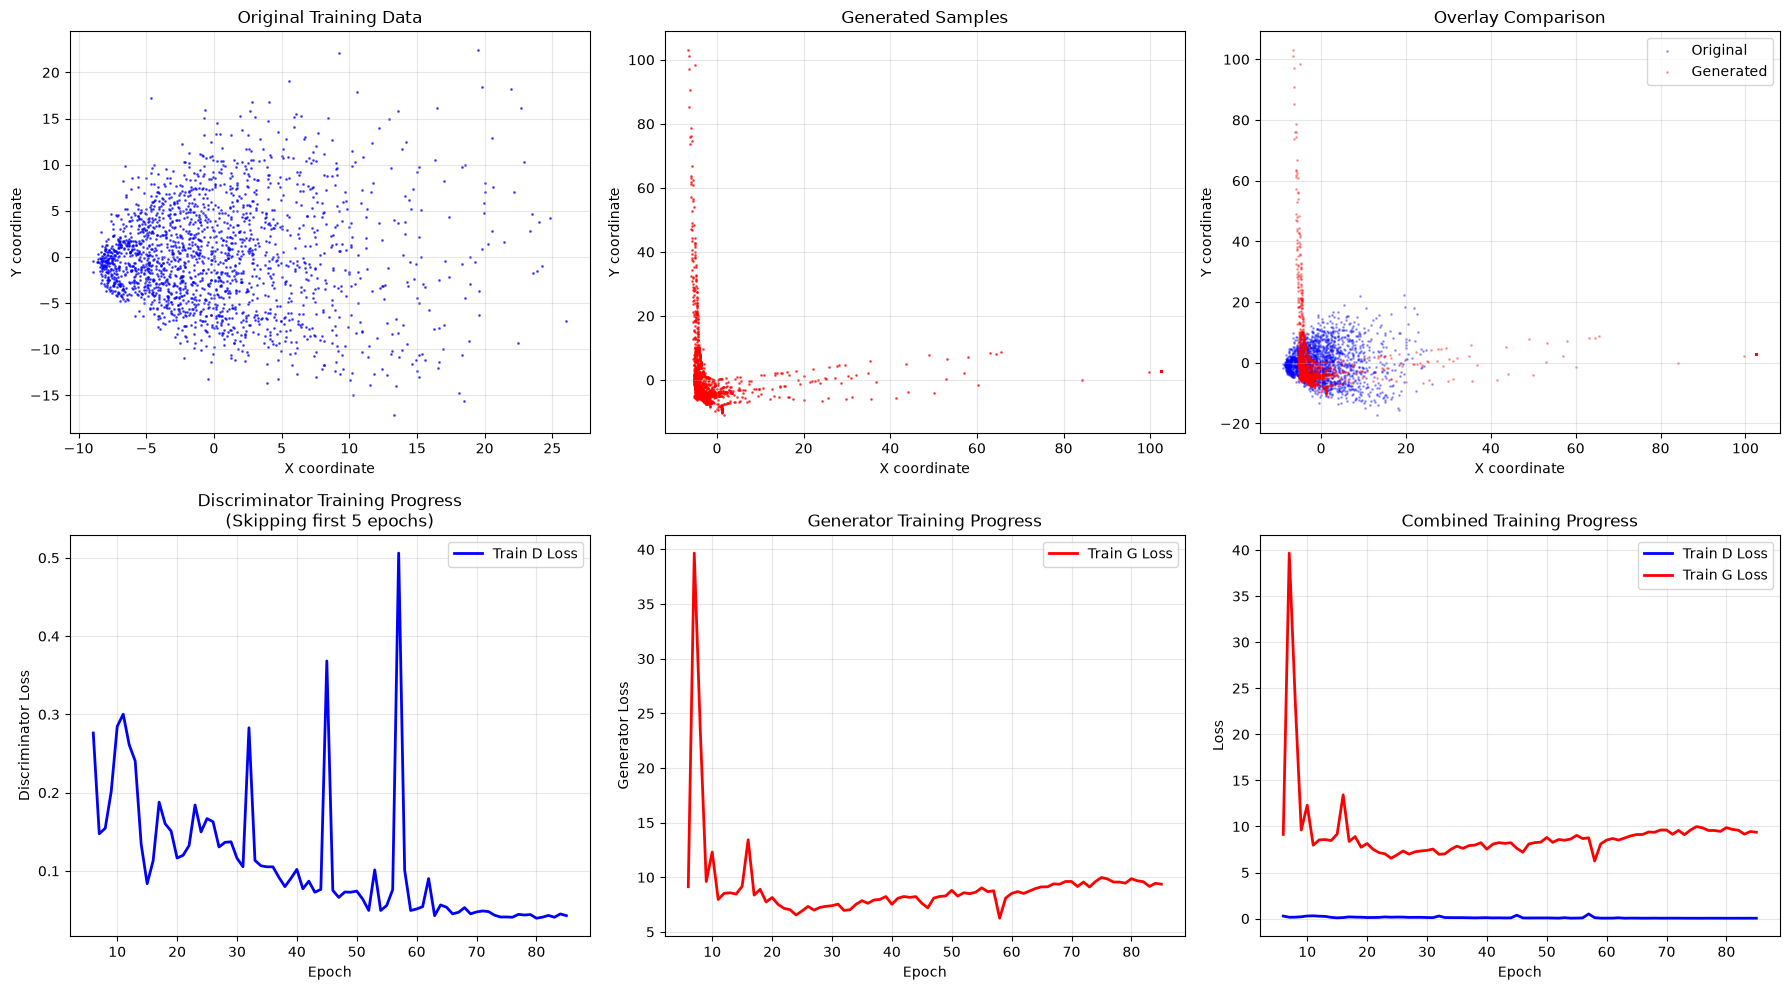

📈 Epoch 85 Summary:
   Train D Loss: 0.0428, Val D Loss: 0.0183
   Train G Loss: 9.3733, Val G Loss: 8.6468

📊 Epoch 86/100
----------------------------------------
Epoch: 86 [0/60000 (0%)]	D_loss: 0.001229	G_loss: 8.792158
Epoch: 86 [6400/60000 (11%)]	D_loss: 0.008807	G_loss: 10.216060
Epoch: 86 [12800/60000 (21%)]	D_loss: 0.040287	G_loss: 11.604519
Epoch: 86 [19200/60000 (32%)]	D_loss: 0.014500	G_loss: 7.554243
Epoch: 86 [25600/60000 (43%)]	D_loss: 0.099683	G_loss: 10.875905
Epoch: 86 [32000/60000 (53%)]	D_loss: 0.030601	G_loss: 8.552826
Epoch: 86 [38400/60000 (64%)]	D_loss: 0.038728	G_loss: 10.997444
Epoch: 86 [44800/60000 (75%)]	D_loss: 0.001680	G_loss: 10.049906
Epoch: 86 [51200/60000 (85%)]	D_loss: 0.042395	G_loss: 8.229990
Epoch: 86 [57600/60000 (96%)]	D_loss: 0.005225	G_loss: 8.537498
====> Epoch: 86 Train D_loss: 0.0323, Train G_loss: 9.4889
====> Epoch: 86 Val D_loss: 0.0245, Val G_loss: 7.2514
📈 Epoch 86 Summary:
   Train D Loss: 0.0323, Val D Loss: 0.0245
   Train G Loss: 9

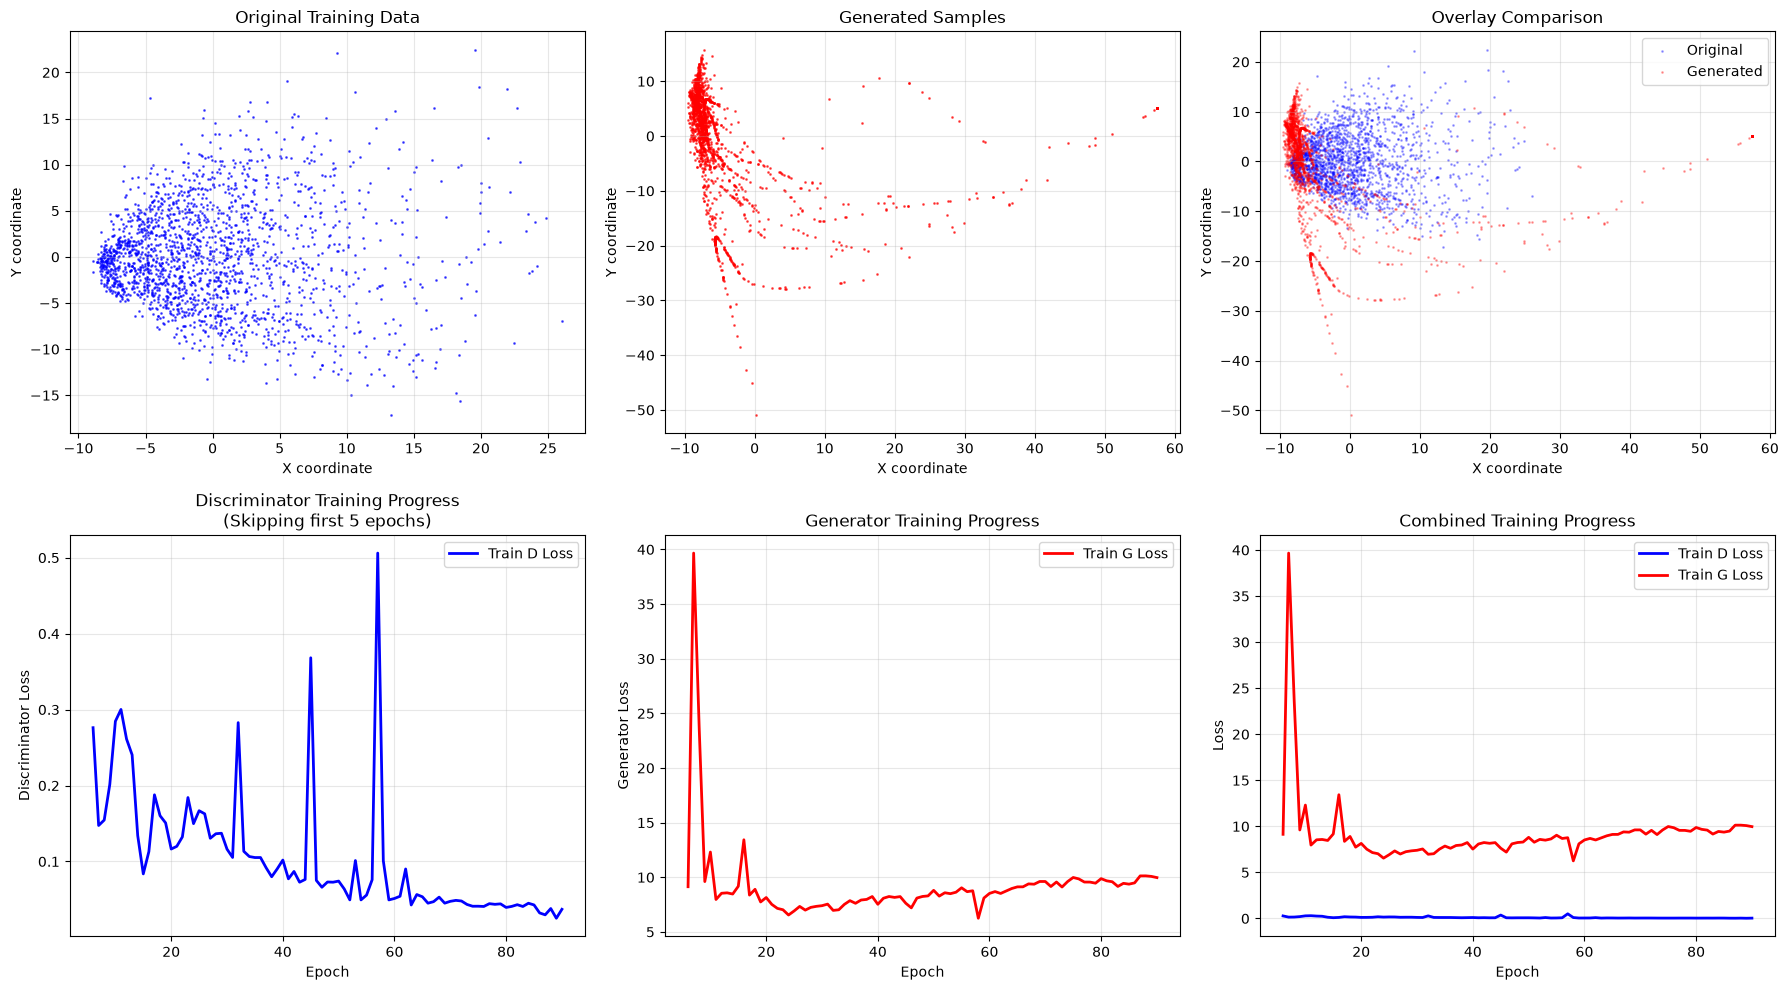

📈 Epoch 90 Summary:
   Train D Loss: 0.0371, Val D Loss: 0.0297
   Train G Loss: 9.9727, Val G Loss: 8.6432

📊 Epoch 91/100
----------------------------------------
Epoch: 91 [0/60000 (0%)]	D_loss: 0.009258	G_loss: 8.769160
Epoch: 91 [6400/60000 (11%)]	D_loss: 0.123161	G_loss: 7.517590
Epoch: 91 [12800/60000 (21%)]	D_loss: 0.005048	G_loss: 6.894138
Epoch: 91 [19200/60000 (32%)]	D_loss: 0.026210	G_loss: 7.939565
Epoch: 91 [25600/60000 (43%)]	D_loss: 0.002247	G_loss: 8.251779
Epoch: 91 [32000/60000 (53%)]	D_loss: 0.023722	G_loss: 11.691614
Epoch: 91 [38400/60000 (64%)]	D_loss: 0.009614	G_loss: 8.214691
Epoch: 91 [44800/60000 (75%)]	D_loss: 0.017442	G_loss: 7.061898
Epoch: 91 [51200/60000 (85%)]	D_loss: 0.009940	G_loss: 8.369562
Epoch: 91 [57600/60000 (96%)]	D_loss: 0.033912	G_loss: 9.875418
====> Epoch: 91 Train D_loss: 0.0351, Train G_loss: 9.8525
====> Epoch: 91 Val D_loss: 0.0256, Val G_loss: 10.2695
📈 Epoch 91 Summary:
   Train D Loss: 0.0351, Val D Loss: 0.0256
   Train G Loss: 9.85

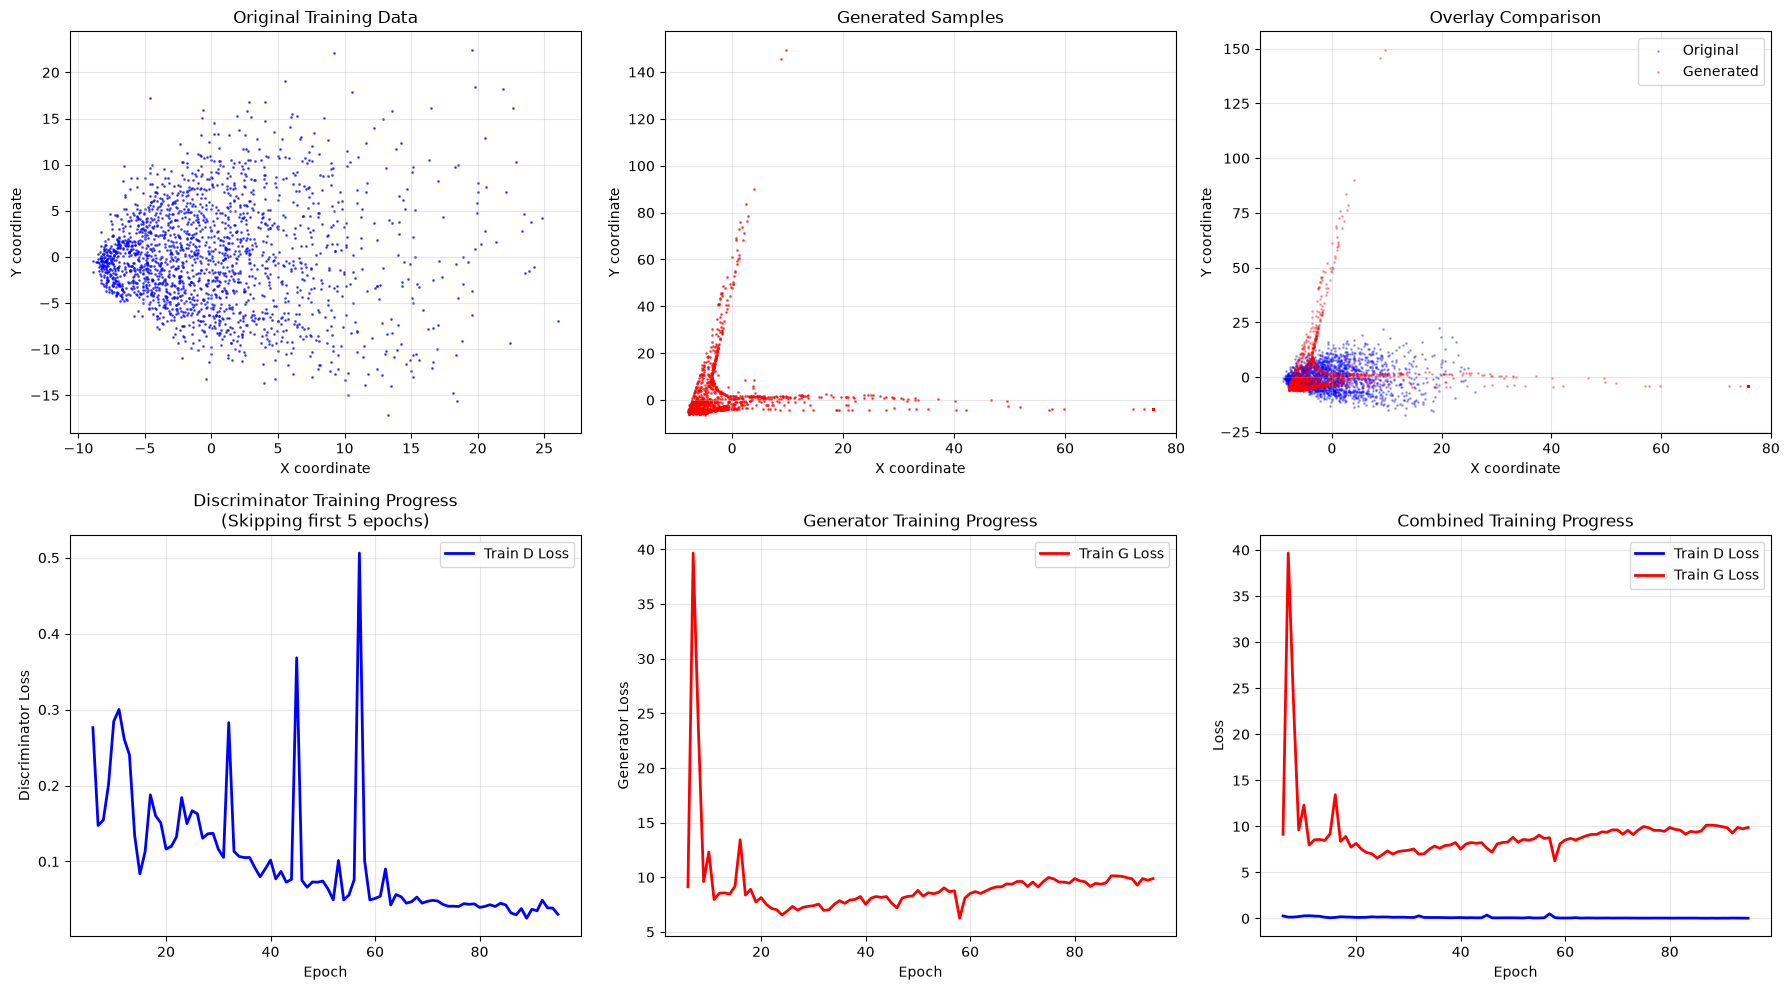

📈 Epoch 95 Summary:
   Train D Loss: 0.0304, Val D Loss: 0.0169
   Train G Loss: 9.8835, Val G Loss: 10.6060

📊 Epoch 96/100
----------------------------------------
Epoch: 96 [0/60000 (0%)]	D_loss: 0.002397	G_loss: 12.064688
Epoch: 96 [6400/60000 (11%)]	D_loss: 0.041427	G_loss: 8.494576
Epoch: 96 [12800/60000 (21%)]	D_loss: 0.012567	G_loss: 8.986018
Epoch: 96 [19200/60000 (32%)]	D_loss: 0.044644	G_loss: 8.403095
Epoch: 96 [25600/60000 (43%)]	D_loss: 0.035450	G_loss: 7.775710
Epoch: 96 [32000/60000 (53%)]	D_loss: 0.010772	G_loss: 9.591421
Epoch: 96 [38400/60000 (64%)]	D_loss: 0.012581	G_loss: 7.377152
Epoch: 96 [44800/60000 (75%)]	D_loss: 0.015695	G_loss: 8.444846
Epoch: 96 [51200/60000 (85%)]	D_loss: 0.035706	G_loss: 6.525884
Epoch: 96 [57600/60000 (96%)]	D_loss: 0.004537	G_loss: 7.974508
====> Epoch: 96 Train D_loss: 0.0527, Train G_loss: 9.6271
====> Epoch: 96 Val D_loss: 0.1055, Val G_loss: 11.3030
📈 Epoch 96 Summary:
   Train D Loss: 0.0527, Val D Loss: 0.1055
   Train G Loss: 9.6

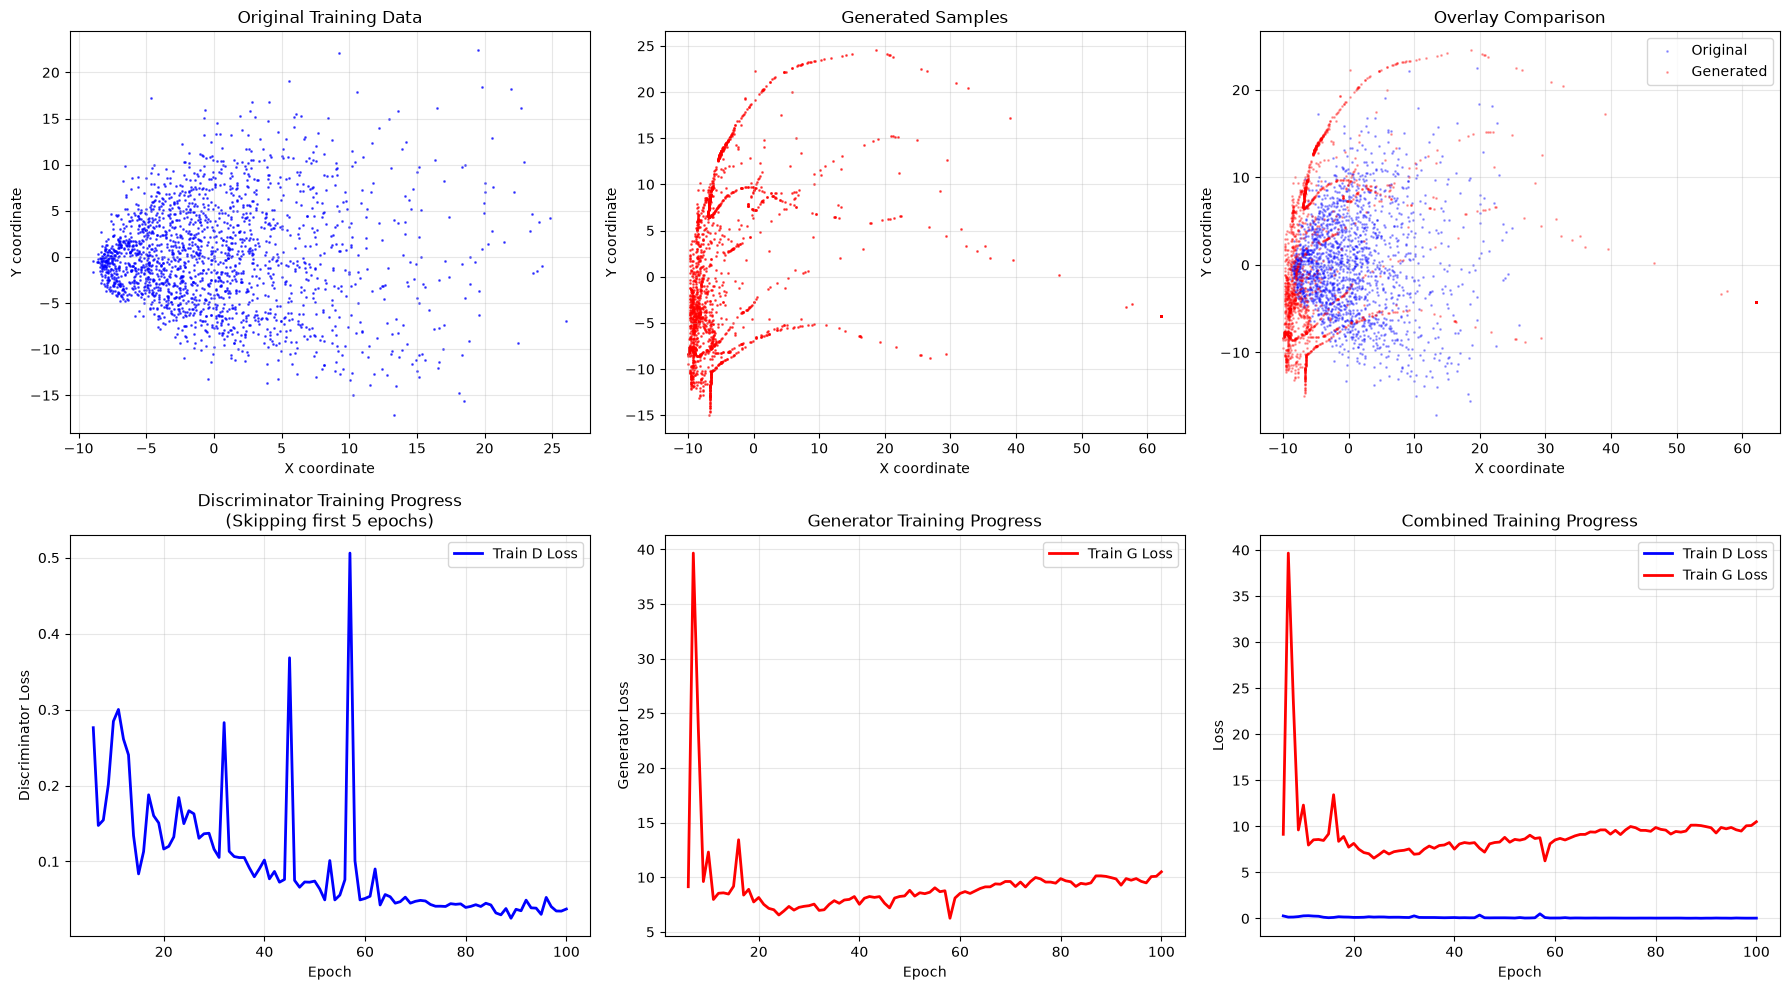

📈 Epoch 100 Summary:
   Train D Loss: 0.0374, Val D Loss: 0.0329
   Train G Loss: 10.5009, Val G Loss: 7.7623

🎉 Training completed!

🎨 Final comprehensive visualization:


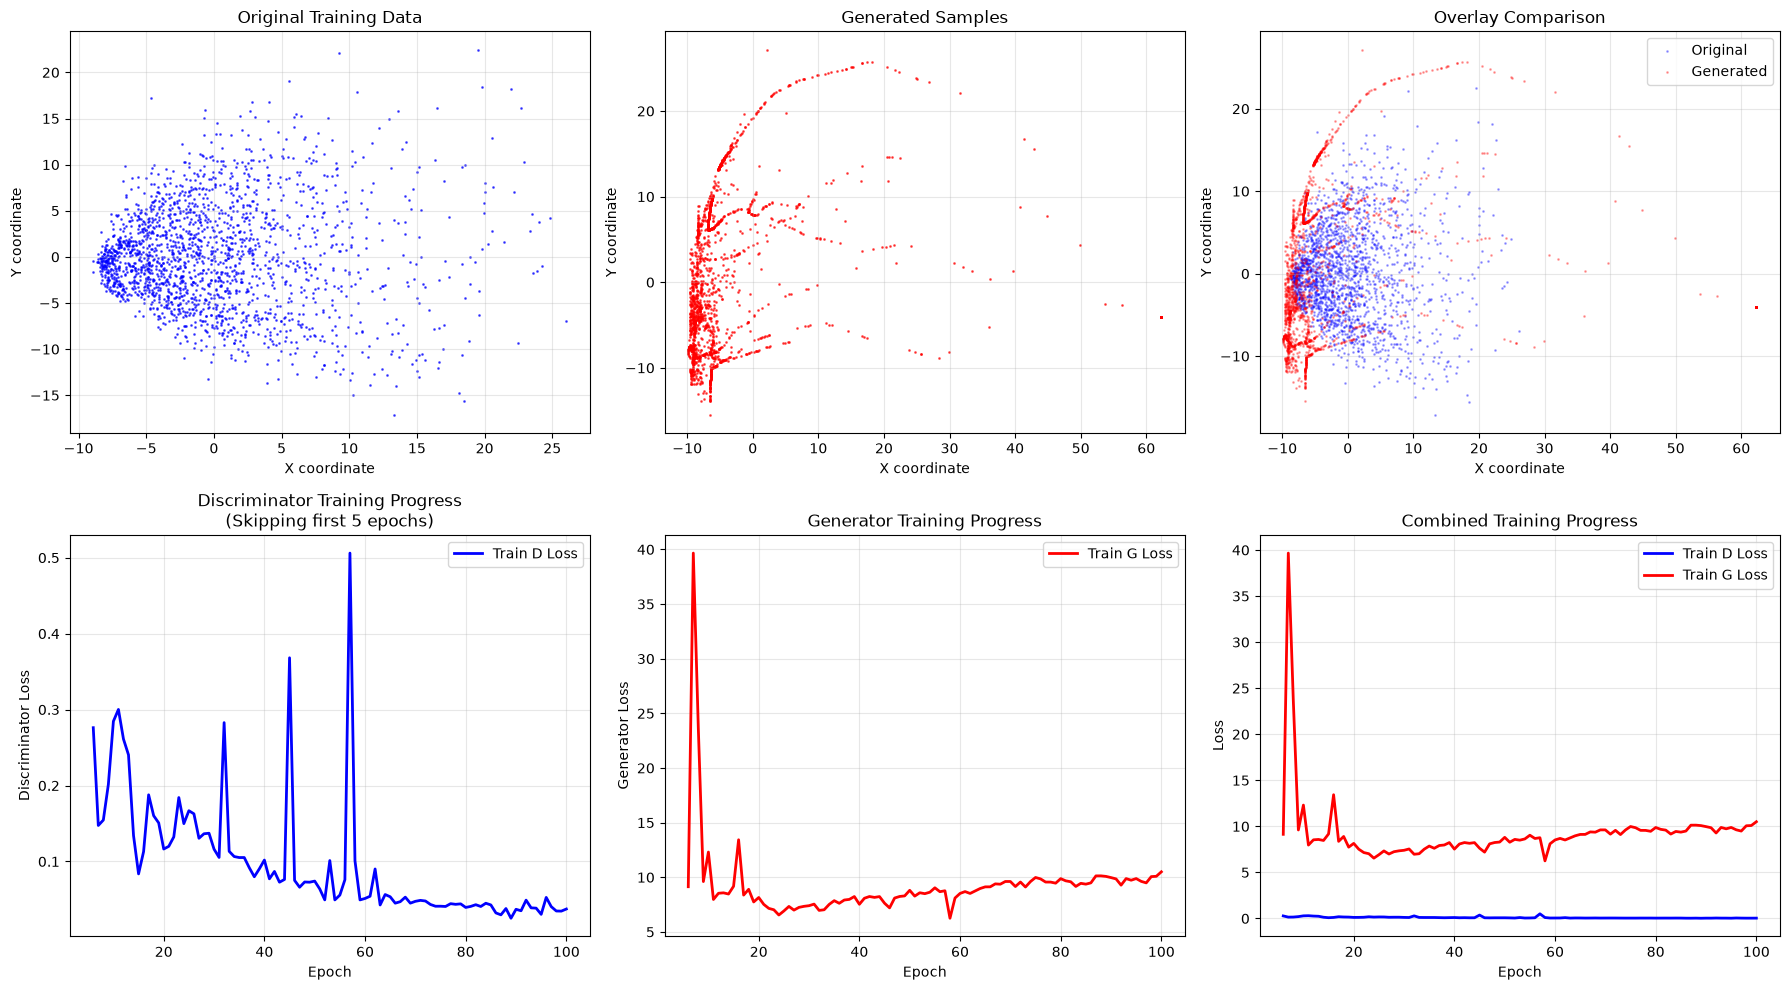

In [14]:
# Training loop
print("🎯 Starting GAN training...")
print("=" * 60)

# Lists to track training progress
train_d_losses = []
train_g_losses = []
val_d_losses = []
val_g_losses = []

# Show initial state (before training)
print("📊 Initial state (before training):")

for epoch in range(1, EPOCHS + 1):
    print(f"\n📊 Epoch {epoch}/{EPOCHS}")
    print("-" * 40)
    
    # Train for one epoch with validation
    train_d_loss, train_g_loss, val_d_loss, val_g_loss = train_epoch_with_validation(epoch)
    
    # Track losses
    train_d_losses.append(train_d_loss)
    train_g_losses.append(train_g_loss)
    val_d_losses.append(val_d_loss)
    val_g_losses.append(val_g_loss)
    
    # Visualize progress every 5 epochs
    if epoch % SAVE_PLT_INTERVAL == 0:
        print(f"\n🎨 Visualizing progress at epoch {epoch}...")
        visualize_training_progress(epoch, train_d_losses, train_g_losses, val_d_losses, val_g_losses)
    
    print(f"📈 Epoch {epoch} Summary:")
    print(f"   Train D Loss: {train_d_loss:.4f}, Val D Loss: {val_d_loss:.4f}")
    print(f"   Train G Loss: {train_g_loss:.4f}, Val G Loss: {val_g_loss:.4f}")

print("\n🎉 Training completed!")
print("=" * 60)

# Save the trained models
# torch.save(generator.state_dict(), 'generator.pth')
# torch.save(discriminator.state_dict(), 'discriminator.pth')
# print("💾 Models saved as 'generator.pth' and 'discriminator.pth'")

# Final comprehensive visualization
print("\n🎨 Final comprehensive visualization:")
visualize_training_progress(EPOCHS, train_d_losses, train_g_losses, val_d_losses, val_g_losses)


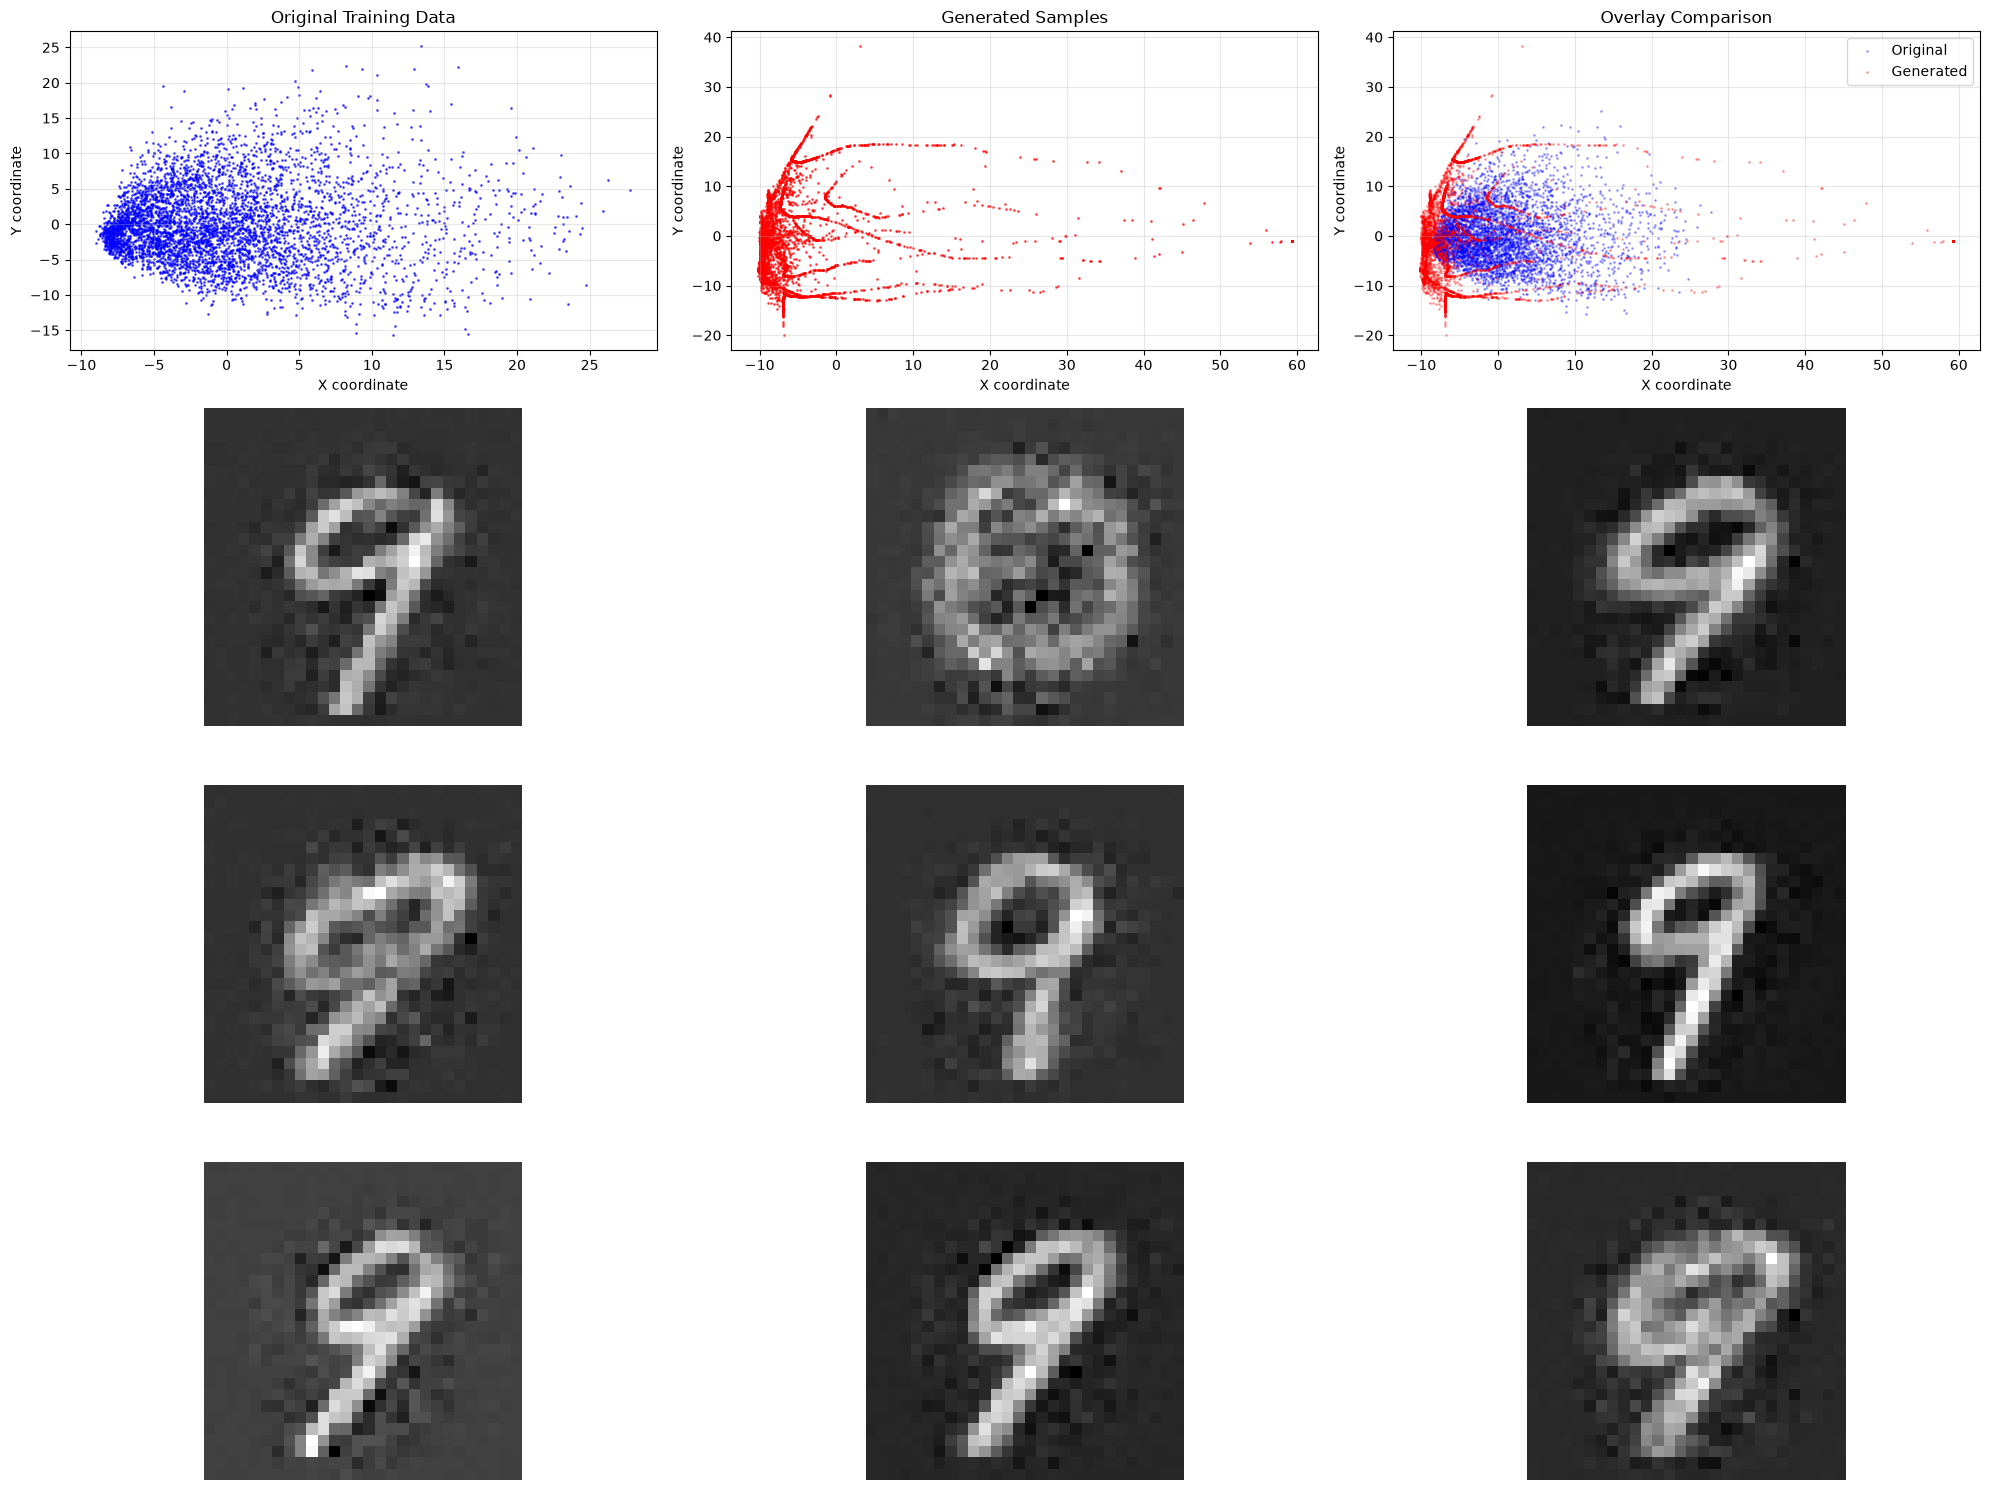

In [15]:
# Generate a large number of samples
generated_samples = generate_samples(5000)

# Create comprehensive visualization
plt.figure(figsize=(20, 15))

train_data_reshaped = np.reshape(train_data.data[:5000], [5000, INPUT_DIM])
data_transformed = pca_fit(train_data_reshaped).transform(train_data_reshaped)
x_transformed = pca_fit(generated_samples).transform(generated_samples)

# Original training data
plt.subplot(4, 3, 1)
plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.6)
plt.title('Original Training Data')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.grid(True, alpha=0.3)

# Generated samples
plt.subplot(4, 3, 2)
plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.6)
plt.title('Generated Samples')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.grid(True, alpha=0.3)

# Overlay comparison
plt.subplot(4, 3, 3)
plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.3, label='Original')
plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.3, label='Generated')
plt.title('Overlay Comparison')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.legend()
plt.grid(True, alpha=0.3)


for i in range(9):
    plt.subplot(4, 3, 3 + i + 1)
    plt.imshow(np.reshape(generated_samples[i], [28, 28]).squeeze(), cmap="gray")
    plt.axis("off")

plt.tight_layout()
plt.show()
